# Multilingual Fact-Check Retrieval at Scale
### An end-to-end Big Data system with PySpark, BM25, SentenceTransformers, FAISS and supervised fine-tuning

---

**Abstract.** False claims circulate across platforms and languages long after professional fact-checkers have debunked them. This project builds a system that takes a social-media post in any language and retrieves the existing fact-checks that address its claim, from a pool of more than 435,000 fact-checks in over 100 languages. The pipeline covers distributed data engineering in PySpark, lexical retrieval (including a distributed inverted index), dense semantic retrieval with SentenceTransformers and FAISS, rank fusion, and supervised fine-tuning with mined hard negatives. It also includes a statistically grounded evaluation and a working multilingual search demo.

### Problem statement
A fact-checker or a platform moderator who sees a suspicious post needs to know quickly whether the claim has *already* been checked. Framed as information retrieval, the input (query) is a post and the output is a ranked list of fact-checks. Five properties make the problem hard:

| Challenge | Why it matters |
|---|---|
| **Scale** | Hundreds of thousands of candidate documents; scoring must be vectorised or distributed. |
| **Multilinguality** | 100+ languages with a heavily skewed distribution; most languages have little data. |
| **Crosslinguality** | About one pair in six links a post and a fact-check written in *different* languages; word overlap is useless there. |
| **Noisy queries** | Posts contain emojis, hashtags, URLs and OCR text extracted from images, and range from a few words to thousands of characters. |
| **Asymmetry** | Fact-check claims are one short sentence, while posts are long and unfocused. |

### Objectives
1. **O1 – Data engineering:** a scalable, reproducible PySpark pipeline that turns raw CSV exports into clean, analysis-ready Parquet tables.
2. **O2 – Lexical baselines:** fast BM25 retrieval on original and machine-translated text, including a distributed Spark implementation.
3. **O3 – Semantic retrieval:** dense retrieval with English and multilingual sentence encoders, indexed with FAISS.
4. **O4 – Learning:** improve the encoders with supervised fine-tuning, and test whether mined hard negatives beat random negatives.
5. **O5 – Rigorous evaluation:** language-aware metrics, confidence intervals, significance tests and error analysis.
6. **O6 – Deployment:** an ANN latency/memory study and an interactive multilingual search demo.

### Research questions
* **RQ1** — Is it better to *translate then retrieve* (English models on machine-translated text) or to use multilingual models directly on the original text?
* **RQ2** — How do lexical (BM25) and semantic (embedding) retrieval compare, and does fusing them help?
* **RQ3** — How much does supervised fine-tuning help, and do BM25-mined hard negatives outperform random negatives?
* **RQ4** — Where do the systems fail (crosslingual pairs, short posts, image-based posts, specific platforms or ratings)?
* **RQ5** — How much accuracy is lost when exact vector search is replaced by approximate search (HNSW, IVF, PQ)?

### System architecture
```
 posts.csv ─┐                                            ┌─► BM25 (original / English) ──────┐
 fact_checks.csv ─► Spark ETL ─► Parquet ─► split 80/10/10 ├─► sentence encoders + FAISS ───────┼─► RRF hybrid ─► evaluation ─► demo
 mapping.csv ─┘   (parse, clean, dedup, lang-norm)          └─► fine-tuned encoders (train split) ┘
```

| Stage | Technology | Design choice |
|---|---|---|
| Ingestion & cleaning | **PySpark** DataFrames, UDFs, window functions, Parquet | Multi-line CSVs parsed in parallel; columnar storage for all downstream steps |
| Exploratory analysis | **Spark SQL**, matplotlib, seaborn | Aggregate in Spark, plot only small summaries |
| Lexical retrieval | Sparse-matrix BM25 (SciPy) + **Spark inverted index** | Exact single-node scoring, plus a scale-out variant |
| Semantic retrieval | **SentenceTransformers** + **FAISS** | Cosine similarity on normalised embeddings |
| Hybrid retrieval | Reciprocal Rank Fusion | Combines complementary lexical and semantic signals without score calibration |
| Fine-tuning | SentenceTransformers Trainer | Baseline: contrastive loss with random negatives; proposed: in-batch loss with BM25 hard negatives |
| Evaluation | NumPy, SciPy | Success@K, MRR, nDCG, 95 % CIs, McNemar tests, same-language bias |
| Serving | FAISS Flat / HNSW / IVF / IVF-PQ, ipywidgets | Latency–memory–recall trade-off; live demo |

### Dataset
The project uses the **MultiClaim** dataset: social-media posts (Facebook, Instagram, Twitter/X, Telegram), professional fact-checks from about 250 fact-checking organisations, and the post–fact-check links. Every text comes in its original language plus an English machine translation, and posts include OCR text extracted from attached images. *Data source and licence:* the MultiClaim dataset is published on Zenodo (record 7737983) for research use only; it must be acknowledged in any report that uses it.

**How to run:** see section 0. Choose `RUN_MODE = "quick"` (≈ 30–45 min on a free Colab T4 GPU) or `RUN_MODE = "full"` (the entire 435k fact-check pool and larger models; an A100 is recommended).

## Table of contents
0. Execution instructions & dependencies
1. Configuration (incl. automatic Google Drive setup on Colab)
2. Data acquisition
3. Distributed ingestion with PySpark
4. Distributed preprocessing — design of the cleaning rules
5. Exploratory data analysis with Spark SQL
6. Train / dev / test split and evaluation pool
7. Evaluation methodology
8. Lexical retrieval: BM25 (+ distributed BM25 in Spark)
9. Semantic retrieval: SentenceTransformers + FAISS
10. Hybrid retrieval (Reciprocal Rank Fusion)
11. Supervised fine-tuning: random vs hard negatives
12. Results and breakdown analyses
13. FAISS scalability study
14. Error analysis
15. Multilingual fact-check retrieval demo
16. Artifacts, findings, limitations and future work

## 0. Execution instructions & dependencies

**Option A — Google Colab (recommended)**
1. In Google Drive, create `My Drive/MultiClaim/dataset/` and upload the three CSV files into it: `posts.csv`, `fact_checks.csv`, `fact_check_post_mapping.csv`. Alternatively, place the zip at `My Drive/MultiClaim/dataset_4.zip`.
2. Open this notebook in Colab and choose *Runtime → Change runtime type → T4 GPU*.
3. Choose *Runtime → Run all* and approve the Google Drive pop-up. The configuration cell detects Colab, mounts Drive and finds the data automatically. Results are copied back to `My Drive/MultiClaim/outputs/` at the end.

**Option B — local machine**
```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt          # or let the next cell install everything
# PySpark needs Java: Java 17+ for pyspark 4.x (Java 8/11/17 for pyspark 3.5)
jupyter lab MultiClaim_Multilingual_FactCheck_Retrieval.ipynb
```
Place the three CSVs in `./dataset/` (or `dataset_4.zip` next to the notebook), or set `DATA_DIR` / `DATA_ZIP` in the configuration cell.

**Hardware guide**

| Mode | Fact-check pool | Eval posts | Models | Typical runtime |
|---|---|---|---|---|
| `quick` | gold + 100k random distractors | 3,000 test posts | MiniLM-L12 (En), Multilingual-MiniLM-L12 (Og/En) | 30–45 min, T4 |
| `full` | all 435k fact-checks | all ≈ 8.8k test posts | GTR-T5-Large, MiniLM-L12, Multilingual-MPNet, LaBSE | 3–6 h, A100 |

Models are downloaded from the Hugging Face Hub on first use (internet access required). Embeddings are cached to disk, so re-running cells is cheap.

In [1]:
# --- 0.1 Install dependencies (safe to re-run; skips what is already installed) ---------------------
import importlib, subprocess, sys

REQUIREMENTS = {
    "pyspark": "pyspark>=3.5",
    "sentence_transformers": "sentence-transformers>=3.0",
    "faiss": "faiss-cpu>=1.7.4",
    "datasets": "datasets>=2.19",
    "accelerate": "accelerate>=1.1",
    "nltk": "nltk>=3.8",
    "seaborn": "seaborn>=0.13",
    "pyarrow": "pyarrow>=14",
    "sklearn": "scikit-learn>=1.3",
    "ipywidgets": "ipywidgets>=8",
}
missing = [spec for mod, spec in REQUIREMENTS.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All Python dependencies already installed.")

Installing: ['faiss-cpu>=1.7.4']


In [2]:
# --- 0.2 Java check for PySpark (installs OpenJDK 17 automatically on Colab / Debian if needed) ------
import os, re, shutil

def java_major():
    if shutil.which("java") is None:
        return None
    out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    m = re.search(r'version "(\d+)(?:\.(\d+))?', out)
    if not m:
        return None
    major = int(m.group(1))
    return int(m.group(2)) if major == 1 else major   # "1.8" -> 8

import pyspark
spark_major = int(pyspark.__version__.split(".")[0])
needed = 17 if spark_major >= 4 else 8
jv = java_major()
print(f"PySpark {pyspark.__version__} | Java {jv} | needs Java >= {needed}")
if jv is None or jv < needed:
    if shutil.which("apt-get"):
        print("Installing OpenJDK 17 ...")
        subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null",
                       shell=True, check=True)
        os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
        os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
        print("Java now:", java_major())
    else:
        raise RuntimeError("Please install Java 17+ (e.g. `brew install openjdk@17` or Temurin) and restart.")

PySpark 4.0.5 | Java 21 | needs Java >= 17


## 1. Configuration
All tunable choices live in this cell. `RUN_MODE` selects a profile, and individual values can be overridden afterwards. On Colab the cell mounts Google Drive and expects the data in `My Drive/MultiClaim/` (see section 0). Edit `DRIVE_PROJECT` if your folder has a different name.

In [3]:
import gc, json, math, time, random, warnings, hashlib, functools, zipfile, ast, unicodedata
from pathlib import Path
from collections import defaultdict, Counter
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

# ----------------------------------------------------------------------------------------------------
RUN_MODE = "quick"                      # "quick" | "full"
SEED = 42
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                              # approve the pop-up
    DRIVE_PROJECT = Path("/content/drive/MyDrive/MultiClaim")  # <- your project folder in Google Drive
    DATA_DIR = str(DRIVE_PROJECT / "dataset")                  # folder with the three CSVs ...
    DATA_ZIP = str(DRIVE_PROJECT / "dataset_4.zip")            # ... or the zip (used if the folder is missing)
    WORK_DIR = Path("/content/multiclaim_work")                # fast local disk; results are copied to Drive at the end
else:
    DRIVE_PROJECT = None
    DATA_DIR = "dataset"                                       # folder with posts.csv, fact_checks.csv, fact_check_post_mapping.csv
    DATA_ZIP = "dataset_4.zip"
    WORK_DIR = Path("multiclaim_work")
# ----------------------------------------------------------------------------------------------------

PROFILES = {
    "quick": dict(
        n_eval_posts=3000,              # sampled from the TEST split
        n_distractor_fc=100_000,        # random non-gold fact-checks added to the pool (None = all 435k)
        min_pairs_group=30,             # min #pairs for a language (pair) to be reported separately
        dense_models=[                  # (label, Hugging Face model id, text version: "en" translated / "og" original)
            ("MiniLM-L12 (En)",        "sentence-transformers/all-MiniLM-L12-v2",                        "en"),
            ("Multi-MiniLM-L12 (Og)",  "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",    "og"),
            ("Multi-MiniLM-L12 (En)",  "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",    "en"),
        ],
        ft_jobs=[                       # (label, base model, version, loss, learning rate)
            ("FT Multi-MiniLM (Og) · RandomNeg [baseline]", "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "og", "ocl",  2e-5),
            ("FT Multi-MiniLM (Og) · MNRL+HardNeg [proposed]",      "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "og", "mnrl", 2e-5),
            ("FT MiniLM-L12 (En) · MNRL+HardNeg [proposed]",        "sentence-transformers/all-MiniLM-L12-v2",                     "en", "mnrl", 2e-5),
        ],
        ft_max_train_pairs=20_000, ft_epochs=1, ft_batch_size=32,
        hardneg_pool_size=100_000,      # fact-checks used for hard-negative mining (train side only)
        max_seq_length=256, encode_batch_size=128,
        spark_bm25_queries=300, spark_bm25_max_df=0.05,
        spark_driver_memory="4g",
    ),
    "full": dict(
        n_eval_posts=None, n_distractor_fc=None, min_pairs_group=100,
        dense_models=[
            ("GTR-T5-Large (En)",      "sentence-transformers/gtr-t5-large",                             "en"),
            ("MiniLM-L12 (En)",        "sentence-transformers/all-MiniLM-L12-v2",                        "en"),
            ("Multi-MPNet (Og)",       "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",    "og"),
            ("Multi-MPNet (En)",       "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",    "en"),
            ("Multi-MiniLM-L12 (Og)",  "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",    "og"),
            ("LaBSE (Og)",             "sentence-transformers/LaBSE",                                    "og"),
        ],
        ft_jobs=[
            ("FT Multi-MPNet (Og) · RandomNeg [baseline]", "sentence-transformers/paraphrase-multilingual-mpnet-base-v2", "og", "ocl",  5e-6),
            ("FT Multi-MPNet (Og) · MNRL+HardNeg [proposed]",      "sentence-transformers/paraphrase-multilingual-mpnet-base-v2", "og", "mnrl", 2e-5),
            ("FT GTR-T5-Large (En) · MNRL+HardNeg [proposed]",     "sentence-transformers/gtr-t5-large",                          "en", "mnrl", 1e-5),
        ],
        ft_max_train_pairs=None, ft_epochs=1, ft_batch_size=32,
        hardneg_pool_size=None,
        max_seq_length=256, encode_batch_size=128,
        spark_bm25_queries=1000, spark_bm25_max_df=0.05,
        spark_driver_memory="8g",
    ),
}
CFG = dict(PROFILES[RUN_MODE])
BM25_K1, BM25_B = 1.2, 0.75             # standard BM25 settings (term-frequency saturation, length normalisation)
TOPK = 100                              # length of every ranked list we keep
OCL_POS_RATIO = 0.30                    # baseline recipe: positives = 30 % of samples (~2.3 random negatives each)
OCL_MARGIN = 0.4                        # baseline recipe: contrastive margin on cosine distance

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
for sub in ["raw", "parquet", "emb", "models", "figures", "results", "spark_bm25", "demo"]:
    (WORK_DIR / sub).mkdir(parents=True, exist_ok=True)
RAW_DIR, PARQ_DIR, EMB_DIR = WORK_DIR / "raw", WORK_DIR / "parquet", WORK_DIR / "emb"
MODEL_DIR, FIG_DIR, RES_DIR = WORK_DIR / "models", WORK_DIR / "figures", WORK_DIR / "results"

TIMINGS = {}
@contextmanager
def timer(name):
    t0 = time.perf_counter()
    yield
    TIMINGS[name] = time.perf_counter() - t0
    print(f"[time] {name}: {TIMINGS[name]:.1f}s")

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

print(f"RUN_MODE={RUN_MODE} | device={DEVICE} | torch {torch.__version__}"
      + (f" | GPU: {torch.cuda.get_device_name(0)}" if DEVICE == "cuda" else ""))

Mounted at /content/drive
RUN_MODE=quick | device=cuda | torch 2.14.1+cu130 | GPU: Tesla T4


## 2. Data acquisition
The archive is extracted once into `WORK_DIR/raw`. macOS metadata folders (`__MACOSX`) are skipped.

In [4]:
def locate_csv_dir():
    required = {"posts.csv", "fact_checks.csv", "fact_check_post_mapping.csv"}
    candidates = [Path(DATA_DIR)] if DATA_DIR else []
    candidates += [RAW_DIR / "dataset", RAW_DIR, Path("dataset"), Path(".")]
    for c in candidates:
        if c.is_dir() and required <= {p.name for p in c.iterdir()}:
            return c
    return None

csv_dir = locate_csv_dir()
if csv_dir is None:
    zpath = Path(DATA_ZIP)
    if not zpath.exists():
        raise FileNotFoundError(f"Neither {DATA_DIR}/ (with the three CSVs) nor {zpath} was found. "
                                "Check the Drive folder names or set DATA_DIR / DATA_ZIP in the configuration cell.")
    (RAW_DIR / "dataset").mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zpath) as zf:
        members = [m for m in zf.namelist() if not m.startswith("__MACOSX") and m.endswith(".csv")]
        for m in members:
            target = RAW_DIR / "dataset" / Path(m).name
            with zf.open(m) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)
    csv_dir = locate_csv_dir()

print("CSV directory:", csv_dir.resolve())
for f in sorted(csv_dir.glob("*.csv")):
    print(f"  {f.name:32s} {f.stat().st_size / 1e6:8.1f} MB")

CSV directory: /content/drive/MyDrive/MultiClaim/dataset
  fact_check_post_mapping.csv           2.8 MB
  fact_checks.csv                     493.2 MB
  posts.csv                           184.8 MB


## 3. Distributed ingestion with PySpark
The CSVs contain multi-line quoted fields (posts and OCR transcripts span several lines), so they are read with `multiLine=True` and RFC-4180 escaping. Everything is read as strings first and typed explicitly afterwards — schema inference on 650 MB of free text is both slow and error-prone.

In [5]:
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import (StructType, StructField, StringType, DoubleType, ArrayType, BooleanType,
                               IntegerType)

spark = (SparkSession.builder
         .appName("MultiClaim-PFCR")
         .master("local[*]")
         .config("spark.driver.memory", CFG["spark_driver_memory"])
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

CSV_OPTS = dict(header=True, multiLine=True, quote='"', escape='"', inferSchema=False, mode="PERMISSIVE")
with timer("spark_read_csv"):
    raw_posts = spark.read.options(**CSV_OPTS).csv(str(csv_dir / "posts.csv"))
    raw_fcs   = spark.read.options(**CSV_OPTS).csv(str(csv_dir / "fact_checks.csv"))
    raw_map   = spark.read.options(**CSV_OPTS).csv(str(csv_dir / "fact_check_post_mapping.csv"))
    raw_counts = {"posts": raw_posts.count(), "fact_checks": raw_fcs.count(), "pairs": raw_map.count()}
print(raw_counts)
raw_posts.printSchema()
raw_fcs.printSchema()

Spark 4.0.5 | cores: 2
[time] spark_read_csv: 37.3s
{'posts': 89139, 'fact_checks': 435252, 'pairs': 105424}
root
 |-- post_id: string (nullable = true)
 |-- post_body: string (nullable = true)
 |-- post_body_en: string (nullable = true)
 |-- post_detected_language: string (nullable = true)
 |-- post_detected_language_iso: string (nullable = true)
 |-- instances: string (nullable = true)
 |-- ocr: string (nullable = true)
 |-- verdicts: string (nullable = true)
 |-- text_v1: string (nullable = true)

root
 |-- fact_check_id: string (nullable = true)
 |-- claim: string (nullable = true)
 |-- title: string (nullable = true)
 |-- claim_en: string (nullable = true)
 |-- title_en: string (nullable = true)
 |-- claim_detected_language: string (nullable = true)
 |-- title_detected_language: string (nullable = true)
 |-- claim_detected_language_iso: string (nullable = true)
 |-- title_detected_language_iso: string (nullable = true)
 |-- instances: string (nullable = true)
 |-- claim_v1: string

In [6]:
# A peek at the raw, still-serialised columns (tuples/lists are stored as Python literals inside the CSV)
raw_posts.select("post_id", F.substring("post_body", 1, 80).alias("post_body"),
                 F.substring("instances", 1, 40).alias("instances"),
                 F.substring("ocr", 1, 60).alias("ocr"), "verdicts", "post_detected_language_iso").show(5, truncate=False)
raw_fcs.select("fact_check_id", F.substring("claim", 1, 70).alias("claim"),
               "claim_detected_language_iso", F.substring("instances", 1, 60).alias("instances"),
               "ratings").show(5, truncate=False)
raw_map.groupBy("relationship").count().orderBy(F.desc("count")).show()

+-------+-----------------------------------------------------------------------------------+----------------------+------------------------------------------------------------+--------+--------------------------+
|post_id|post_body                                                                          |instances             |ocr                                                         |verdicts|post_detected_language_iso|
+-------+-----------------------------------------------------------------------------------+----------------------+------------------------------------------------------------+--------+--------------------------+
|2731   |"Don Quijote soy, y mi profesión la de andante caballería. Son mis leyes, el des   |[(None, 'ig')]        |NULL                                                        |NULL    |spa                       |
|2733   |Circula nas redes sociais um vídeo do ex-presidiário Lula negando descer do tran   |[(1652304730.0, 'ig')]|[('LULA PUTAÇO NA LIVE MUTIC

## 4. Distributed preprocessing — design of the cleaning rules
Each rule below targets a concrete problem found while inspecting the raw data. All of them run as Spark transformations; Python UDFs execute in parallel worker processes.

| Step | Rule | Rationale | Implementation |
|---|---|---|---|
| Parse serialised fields | `instances`, `ocr`, `verdicts`, `ratings` are stored as Python literals | They must become typed columns before any analysis | `ast.literal_eval` UDFs returning Spark structs |
| Remove unusable claims | Drop fact-checks whose claim is shorter than 10 characters | Such "claims" are labels or fragments and cannot be matched meaningfully | Spark filter |
| Remove URLs | Strip `http…` / `www…` tokens | URLs are post-specific and add noise to both lexical and semantic matching | Regex in UDF |
| Filter noisy text | A post text or OCR transcript is discarded if it is shorter than 25 characters or less than 50 % alphabetic; individual OCR lines shorter than 5 characters or less than 50 % alphabetic are dropped | OCR on memes and screenshots produces symbol soup; very short texts carry no claim | UDF `build_post_text` |
| Keep image text | Post representation = main text **+ cleaned OCR** | Many claims live inside images rather than in the caption | UDF |
| Fact-check representation | The **claim** field only | It is the most concise statement of what was checked; titles are often headline-style and redundant (the title is kept in Parquet for experiments) | Column selection |
| De-duplicate posts | Posts with identical cleaned text are merged, and their links are re-mapped to one canonical id | Prevents the same text from landing in both train and test | Window function |
| Normalise languages | Croatian/Bosnian/Serbian → `hbs`, Indonesian/Malay → `msa`, Filipino → `tgl` | Language detectors cannot reliably tell these close varieties apart; merging them avoids spurious "crosslingual" pairs | `create_map` lookup |

"Alphabetic" uses Unicode categories *L* (letters) and *M* (combining marks). Otherwise the vowel signs of abugida scripts (Devanagari, Bengali, Thai, …) would make Hindi or Thai text look like noise.

In [7]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
WS_RE = re.compile(r"\s+")

def alpha_ratio(s):
    chars = [c for c in s if not c.isspace()]
    if not chars:
        return 0.0
    return sum(unicodedata.category(c)[0] in "LM" for c in chars) / len(chars)

def norm_ws(s):
    return WS_RE.sub(" ", s or "").strip()

def strip_urls(s):
    return norm_ws(URL_RE.sub(" ", s or ""))

def is_noisy(s, min_len=25):
    return len(s) < min_len or alpha_ratio(s) < 0.5

def clean_ocr(s):
    lines = [strip_urls(l) for l in (s or "").splitlines()]
    return norm_ws(" ".join(l for l in lines if len(l) >= 5 and alpha_ratio(l) >= 0.5))

def safe_eval(s):
    if s is None:
        return None
    try:
        return ast.literal_eval(s)
    except Exception:
        return None

VERDICT_MAP = {"false": "False information", "false information": "False information",
               "partly false": "Partly false information", "partly false information": "Partly false information",
               "missing context": "Missing context", "altered photo": "Altered photo/video",
               "altered video": "Altered photo/video", "altered photo/video": "Altered photo/video"}

POST_META = StructType([
    StructField("ts", DoubleType()), StructField("platforms", ArrayType(StringType())),
    StructField("ocr_og", StringType()), StructField("ocr_en", StringType()),
    StructField("verdict", StringType())])

@F.udf(POST_META)
def parse_post_meta(instances, ocr, verdicts):
    inst = safe_eval(instances) or []
    ts = [float(t) for t, _ in inst if t is not None]
    platforms = sorted({p for _, p in inst if p})
    ocr_items = safe_eval(ocr) or []
    ocr_og = "\n".join(str(o[0]) for o in ocr_items if o and o[0])
    ocr_en = "\n".join(str(o[1]) for o in ocr_items if len(o) > 1 and o[1])
    v = safe_eval(verdicts) or []
    verdict = next((VERDICT_MAP[x.lower()] for x in v if x and x.lower() in VERDICT_MAP), "Other" if v else "No rating")
    return (min(ts) if ts else None, platforms, ocr_og, ocr_en, verdict)

POST_TEXT = StructType([StructField("text_og", StringType()), StructField("text_en", StringType()),
                        StructField("keep", BooleanType()), StructField("has_ocr", BooleanType())])

@F.udf(POST_TEXT)
def build_post_text(body, body_en, ocr_og, ocr_en):
    b, be = strip_urls(body), strip_urls(body_en)
    o, oe = clean_ocr(ocr_og), clean_ocr(ocr_en)
    use_body, use_ocr = (b and not is_noisy(b)), (o and not is_noisy(o))
    og = " ".join(x for x, u in ((b, use_body), (o, use_ocr)) if u)
    en = " ".join(x for x, u in ((be or b, use_body), (oe or o, use_ocr)) if u)
    return (og, en, bool(use_body or use_ocr), bool(use_ocr))

FC_META = StructType([StructField("ts", DoubleType()), StructField("domain", StringType()),
                      StructField("rating", StringType())])

@F.udf(FC_META)
def parse_fc_meta(instances, ratings):
    inst = safe_eval(instances) or []
    ts = [float(t) for t, _ in inst if t is not None]
    url = next((u for _, u in inst if u), "")
    m = re.match(r"https?://(?:www\.)?([^/]+)", url or "")
    r = safe_eval(ratings) or []
    return (min(ts) if ts else None, m.group(1).lower() if m else None, (r[0] if r else None))

LANG_NORM = {"bos": "hbs", "hrv": "hbs", "srp": "hbs", "ind": "msa", "zlm": "msa", "fil": "tgl"}
lang_map = F.create_map(*[F.lit(x) for kv in LANG_NORM.items() for x in kv])
def norm_lang(col):
    return F.coalesce(lang_map[F.col(col)], F.col(col))

In [8]:
with timer("spark_preprocess"):
    # ---------------- fact-checks ----------------
    fcs_sdf = (raw_fcs
        .withColumn("fact_check_id", F.col("fact_check_id").cast(IntegerType()))
        .withColumn("claim_og", F.udf(strip_urls)("claim"))
        .withColumn("claim_en", F.udf(strip_urls)("claim_en"))
        .withColumn("meta", parse_fc_meta("instances", "ratings"))
        .filter(F.length("claim_og") >= 10)                                   # drop label-like / fragment claims
        .dropDuplicates(["claim_og"])                                         # one row per distinct claim text
        .select("fact_check_id", "claim_og", "claim_en",
                F.coalesce(F.col("title"), F.lit("")).alias("title_og"),
                norm_lang("claim_detected_language_iso").alias("lang"),
                F.col("meta.ts").alias("ts"), F.col("meta.domain").alias("domain"),
                F.col("meta.rating").alias("rating"))
        .withColumn("year", F.year(F.from_unixtime("ts"))))

    # ---------------- posts ----------------
    posts_sdf = (raw_posts
        .withColumn("post_id", F.col("post_id").cast(IntegerType()))
        .withColumn("meta", parse_post_meta("instances", "ocr", "verdicts"))
        .withColumn("txt", build_post_text("post_body", "post_body_en", "meta.ocr_og", "meta.ocr_en"))
        .select("post_id", F.col("txt.text_og").alias("text_og"), F.col("txt.text_en").alias("text_en"),
                F.col("txt.keep").alias("keep"), F.col("txt.has_ocr").alias("has_ocr"),
                norm_lang("post_detected_language_iso").alias("lang"),
                F.col("meta.ts").alias("ts"), F.col("meta.platforms").alias("platforms"),
                F.col("meta.verdict").alias("verdict"))
        .withColumn("platform", F.element_at("platforms", 1))
        .withColumn("year", F.year(F.from_unixtime("ts"))))
    posts_sdf = posts_sdf.cache()
    n_noisy = posts_sdf.filter(~F.col("keep")).count()
    posts_sdf = posts_sdf.filter("keep").drop("keep")

    # de-duplicate posts with identical cleaned text -> canonical (smallest) post_id
    w = Window.partitionBy("text_og")
    canon = posts_sdf.withColumn("canonical_id", F.min("post_id").over(w)).select("post_id", "canonical_id")
    posts_dedup = posts_sdf.join(canon, "post_id").filter("post_id = canonical_id").drop("canonical_id")

    # ---------------- pairs ----------------
    pairs_sdf = (raw_map
        .select(F.col("fact_check_id").cast(IntegerType()).alias("fact_check_id"),
                F.col("post_id").cast(IntegerType()).alias("post_id"), "relationship")
        .join(canon, "post_id").drop("post_id").withColumnRenamed("canonical_id", "post_id")
        .join(fcs_sdf.select("fact_check_id"), "fact_check_id", "left_semi")
        .dropDuplicates(["fact_check_id", "post_id"]))
    posts_dedup = posts_dedup.join(pairs_sdf.select("post_id").distinct(), "post_id", "left_semi")
    pairs_sdf = pairs_sdf.join(posts_dedup.select("post_id"), "post_id", "left_semi")

    posts_dedup.write.mode("overwrite").parquet(str(PARQ_DIR / "posts"))
    fcs_sdf.write.mode("overwrite").parquet(str(PARQ_DIR / "fact_checks"))
    pairs_sdf.write.mode("overwrite").parquet(str(PARQ_DIR / "pairs"))
    posts_sdf.unpersist()

posts_s = spark.read.parquet(str(PARQ_DIR / "posts"))
fcs_s = spark.read.parquet(str(PARQ_DIR / "fact_checks"))
pairs_s = spark.read.parquet(str(PARQ_DIR / "pairs"))
clean_counts = {"posts": posts_s.count(), "fact_checks": fcs_s.count(), "pairs": pairs_s.count()}
print(f"Noisy posts removed: {n_noisy:,}")
print(pd.DataFrame({"raw": raw_counts, "clean": clean_counts}).assign(removed=lambda d: d.raw - d.clean))

[time] spark_preprocess: 173.1s
Noisy posts removed: 421
                raw   clean  removed
posts         89139   88443      696
fact_checks  435252  435110      142
pairs        105424  104608      816


## 5. Exploratory data analysis with Spark SQL
All aggregations run in Spark; only small aggregated tables are brought to the driver for plotting. `collect_pd` converts via `collect()`, which avoids Arrow/pandas version coupling.

In [9]:
def collect_pd(sdf):
    rows = sdf.collect()
    return pd.DataFrame([r.asDict() for r in rows]) if rows else pd.DataFrame(columns=sdf.columns)

posts_s.createOrReplaceTempView("posts")
fcs_s.createOrReplaceTempView("fcs")
pairs_s.createOrReplaceTempView("pairs")
spark.sql("""
  CREATE OR REPLACE TEMP VIEW pairs_x AS
  SELECT p.*, po.lang AS post_lang, f.lang AS fc_lang, (po.lang <> f.lang) AS is_cross,
         po.platform, po.verdict, po.year AS post_year
  FROM pairs p JOIN posts po USING (post_id) JOIN fcs f USING (fact_check_id)""")

stats = collect_pd(spark.sql("""
  SELECT (SELECT COUNT(*) FROM posts)                         AS posts,
         (SELECT COUNT(DISTINCT lang) FROM posts)             AS post_languages,
         (SELECT COUNT(*) FROM fcs)                           AS fact_checks,
         (SELECT COUNT(DISTINCT lang) FROM fcs)               AS fc_languages,
         (SELECT COUNT(DISTINCT domain) FROM fcs)             AS fc_sources,
         (SELECT COUNT(*) FROM pairs_x)                       AS pairs,
         (SELECT SUM(CAST(NOT is_cross AS INT)) FROM pairs_x) AS monolingual_pairs,
         (SELECT SUM(CAST(is_cross AS INT)) FROM pairs_x)     AS crosslingual_pairs""")).T
stats.columns = ["value"]
stats["value"] = stats["value"].map(lambda v: f"{int(v):,}")
display(stats)

,value
posts,"88,443"
post_languages,145
fact_checks,"435,110"
fc_languages,119
fc_sources,254
pairs,"104,608"
monolingual_pairs,"87,385"
crosslingual_pairs,"17,223"


> **Observation.** The corpus contains about 88k posts, 435k fact-checks and 105k links. Roughly one link in six is crosslingual, and posts span 140+ detected language codes. Because a larger candidate pool makes retrieval harder (every extra fact-check is a potential false positive), the pool size is reported with every result.

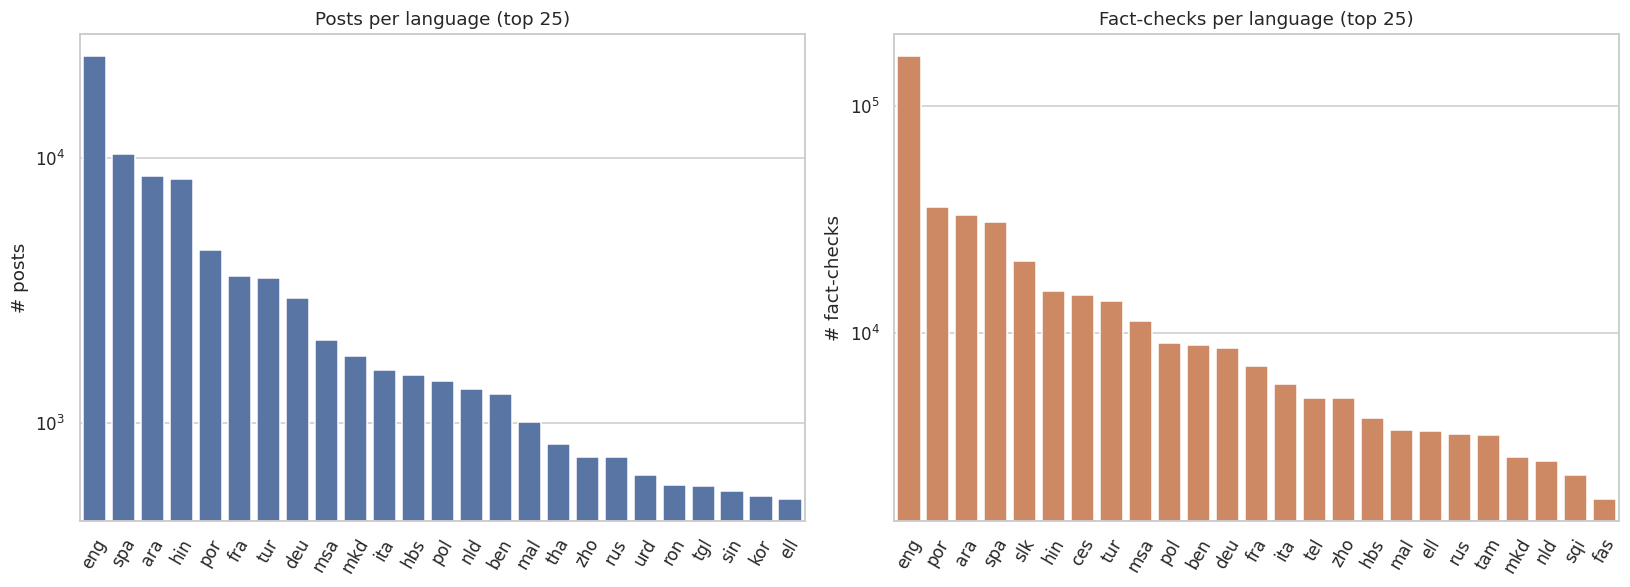

Languages with >= 50 posts: 45 | with >= 50 fact-checks: 53


In [10]:
lang_posts = collect_pd(spark.sql("SELECT lang, COUNT(*) AS n FROM posts GROUP BY lang"))
lang_fcs = collect_pd(spark.sql("SELECT lang, COUNT(*) AS n FROM fcs GROUP BY lang"))
lang = (lang_posts.merge(lang_fcs, on="lang", how="outer", suffixes=("_posts", "_fact_checks"))
        .fillna(0).sort_values("n_posts", ascending=False))
top = lang.head(25)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=top, x="lang", y="n_posts", ax=axes[0], color="#4C72B0")
axes[0].set(title="Posts per language (top 25)", xlabel="", ylabel="# posts", yscale="log")
top_fc = lang.sort_values("n_fact_checks", ascending=False).head(25)
sns.barplot(data=top_fc, x="lang", y="n_fact_checks", ax=axes[1], color="#DD8452")
axes[1].set(title="Fact-checks per language (top 25)", xlabel="", ylabel="# fact-checks", yscale="log")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); savefig("eda_languages")
print(f"Languages with >= 50 posts: {(lang.n_posts >= 50).sum()} | with >= 50 fact-checks: {(lang.n_fact_checks >= 50).sum()}")

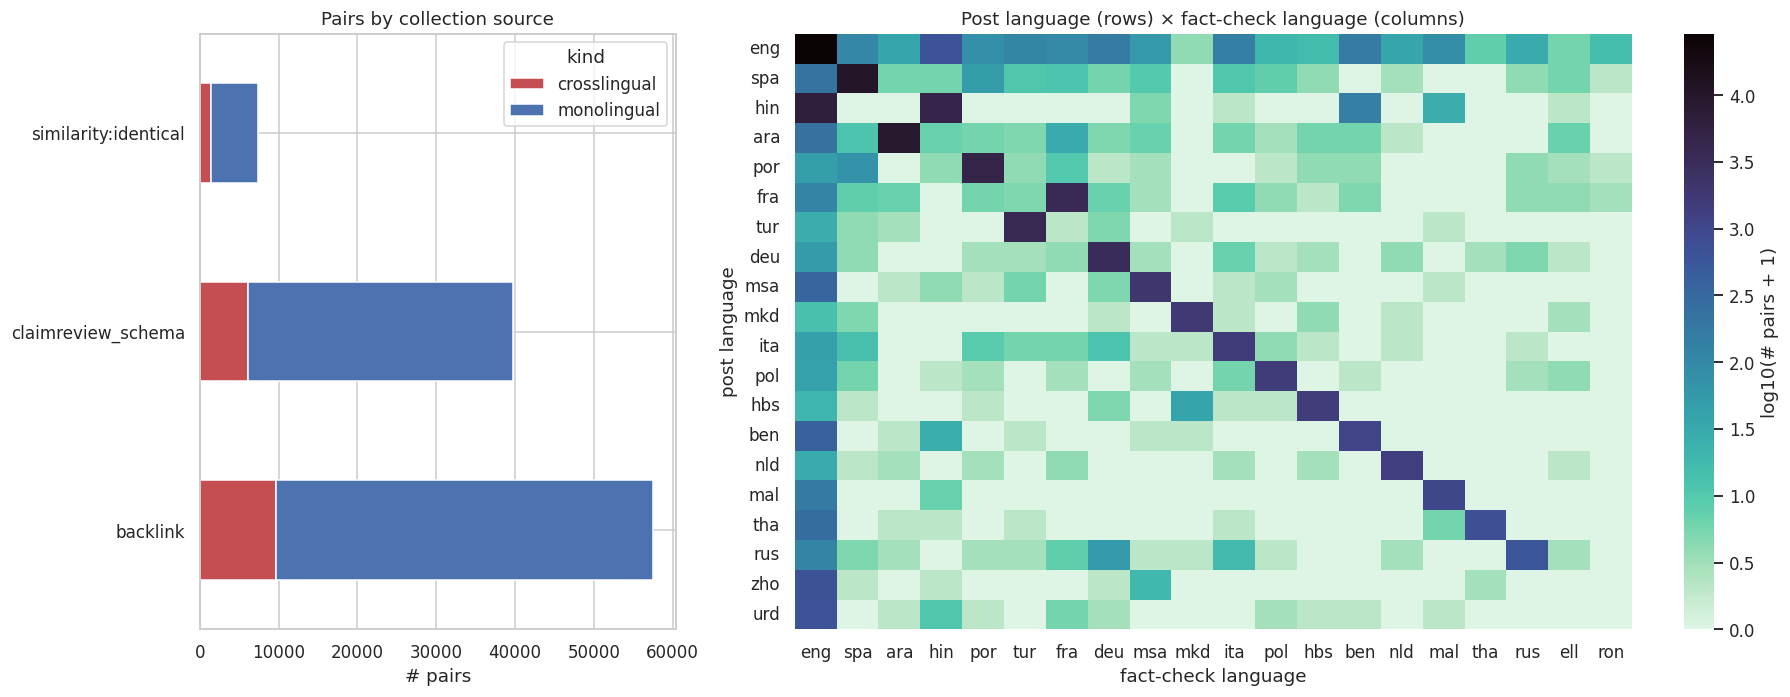

Most frequent crosslingual combinations (fact-check-post):
   pair    n
eng-hin 6303
eng-zho  715
hin-eng  661
eng-urd  656
eng-tgl  609
eng-sin  512
eng-ben  423
eng-msa  342
eng-tha  264
eng-ara  237


In [11]:
# Pair composition: collection source x language relation, and the post-language x fact-check-language matrix
comp = collect_pd(spark.sql("""
  SELECT relationship, CASE WHEN is_cross THEN 'crosslingual' ELSE 'monolingual' END AS kind, COUNT(*) AS n
  FROM pairs_x GROUP BY 1, 2"""))
comp_p = comp.pivot(index="relationship", columns="kind", values="n").fillna(0)

matrix = collect_pd(spark.sql("SELECT post_lang, fc_lang, COUNT(*) AS n FROM pairs_x GROUP BY 1, 2"))
top_post = matrix.groupby("post_lang").n.sum().nlargest(20).index
top_fc = matrix.groupby("fc_lang").n.sum().nlargest(20).index
M = (matrix[matrix.post_lang.isin(top_post) & matrix.fc_lang.isin(top_fc)]
     .pivot(index="post_lang", columns="fc_lang", values="n").fillna(0).loc[top_post, top_fc])

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 2.2]})
comp_p.plot.barh(stacked=True, ax=axes[0], color=["#C44E52", "#4C72B0"])
axes[0].set(title="Pairs by collection source", xlabel="# pairs", ylabel="")
sns.heatmap(np.log10(M + 1), ax=axes[1], cmap="mako_r", cbar_kws={"label": "log10(# pairs + 1)"})
axes[1].set(title="Post language (rows) × fact-check language (columns)", xlabel="fact-check language", ylabel="post language")
plt.tight_layout(); savefig("eda_pairs")

cross_top = (matrix[matrix.post_lang != matrix.fc_lang].sort_values("n", ascending=False).head(10)
             .assign(pair=lambda d: d.fc_lang + "-" + d.post_lang)[["pair", "n"]])
print("Most frequent crosslingual combinations (fact-check-post):")
print(cross_top.to_string(index=False))

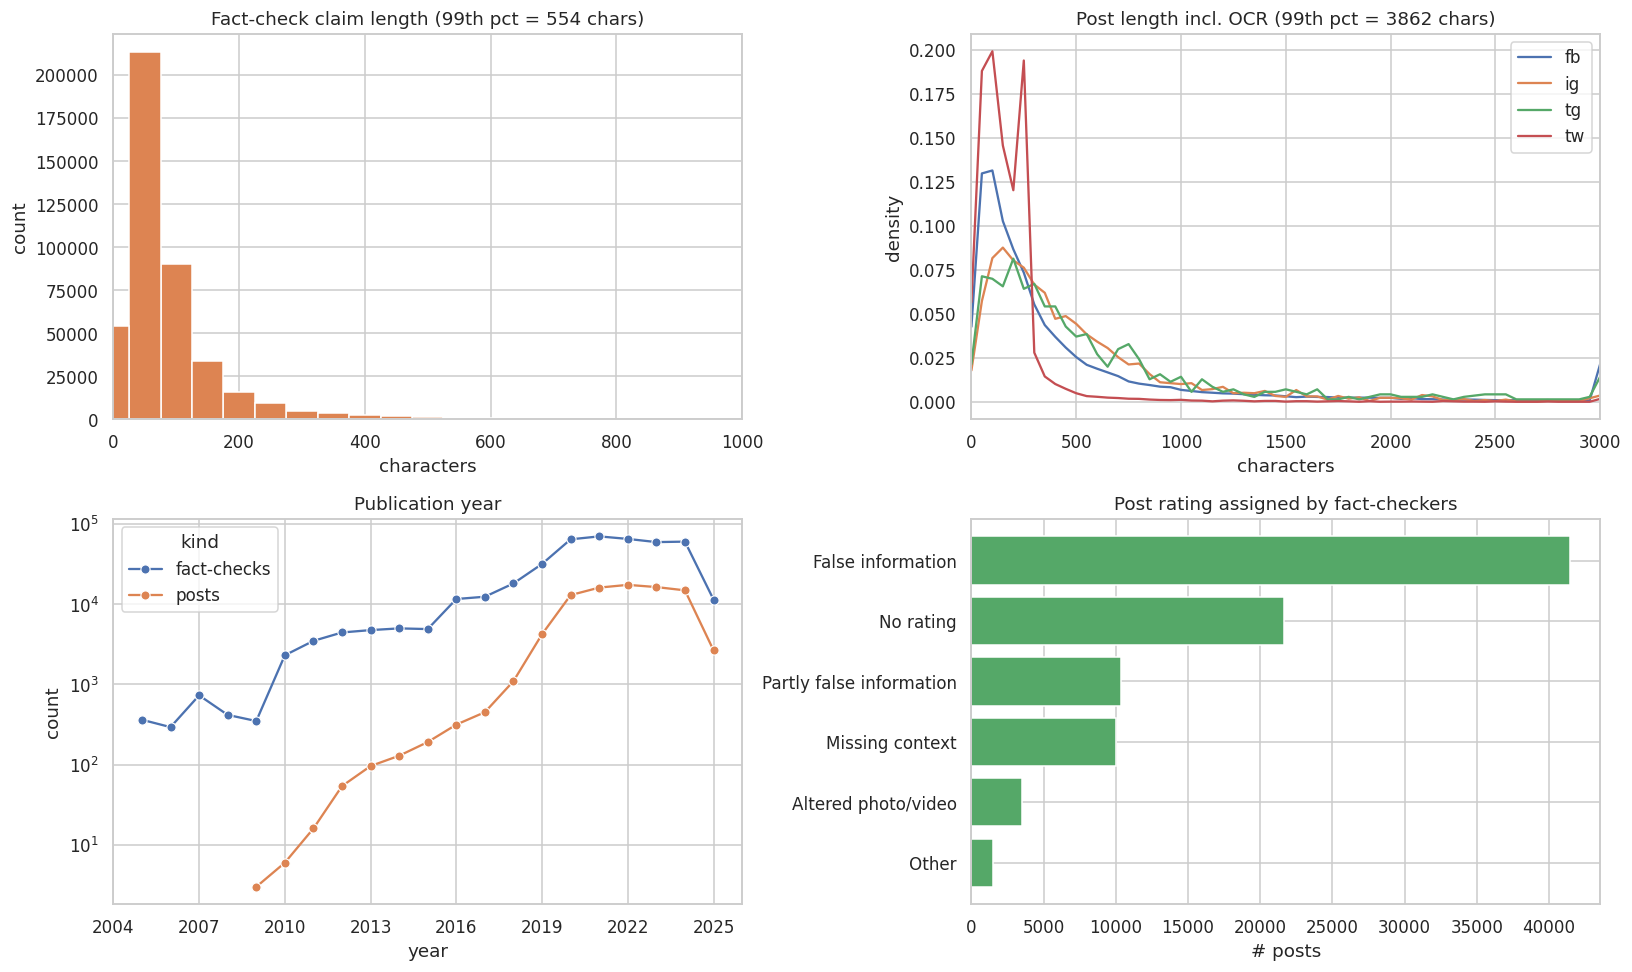

platform,fb,tw,ig,tg
n,71080,12804,3858,701


In [12]:
# Text lengths computed as Spark histograms; timeline; platforms; ratings
def len_hist(table, col, extra=""):
    return collect_pd(spark.sql(f"""
        SELECT LEAST(FLOOR(LENGTH({col}) / 50) * 50, 3000) AS bucket, {extra} COUNT(*) AS n
        FROM {table} GROUP BY 1 {', 2' if extra else ''}"""))

fc_len = len_hist("fcs", "claim_og")
post_len = len_hist("posts", "text_og", "COALESCE(platform, 'unknown') AS platform,")
q = collect_pd(spark.sql("""SELECT percentile_approx(LENGTH(claim_og), 0.99) AS fc_p99 FROM fcs""")).iloc[0, 0]
q2 = collect_pd(spark.sql("""SELECT percentile_approx(LENGTH(text_og), 0.99) AS post_p99 FROM posts""")).iloc[0, 0]

years = collect_pd(spark.sql("""
   SELECT year, 'posts' AS kind, COUNT(*) AS n FROM posts WHERE year BETWEEN 2005 AND 2025 GROUP BY year
   UNION ALL SELECT year, 'fact-checks', COUNT(*) FROM fcs WHERE year BETWEEN 2005 AND 2025 GROUP BY year"""))
plat = collect_pd(spark.sql("SELECT COALESCE(platform,'unknown') AS platform, COUNT(*) AS n FROM posts GROUP BY 1"))
verd = collect_pd(spark.sql("SELECT verdict, COUNT(*) AS n FROM posts GROUP BY 1"))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].bar(fc_len.bucket, fc_len.n, width=50, color="#DD8452")
axes[0, 0].set(title=f"Fact-check claim length (99th pct = {q} chars)", xlabel="characters", ylabel="count", xlim=(0, 1000))
for p_, g in post_len.groupby("platform"):
    g = g.sort_values("bucket"); axes[0, 1].plot(g.bucket, g.n / g.n.sum(), label=p_)
axes[0, 1].set(title=f"Post length incl. OCR (99th pct = {q2} chars)", xlabel="characters", ylabel="density", xlim=(0, 3000))
axes[0, 1].legend()
sns.lineplot(data=years.sort_values("year"), x="year", y="n", hue="kind", marker="o", ax=axes[1, 0])
axes[1, 0].set(title="Publication year", yscale="log", ylabel="count")
axes[1, 0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
v = verd.sort_values("n", ascending=True)
axes[1, 1].barh(v.verdict, v.n, color="#55A868")
axes[1, 1].set(title="Post rating assigned by fact-checkers", xlabel="# posts")
plt.tight_layout(); savefig("eda_lengths_time_ratings")
display(plat.sort_values("n", ascending=False).set_index("platform").T)

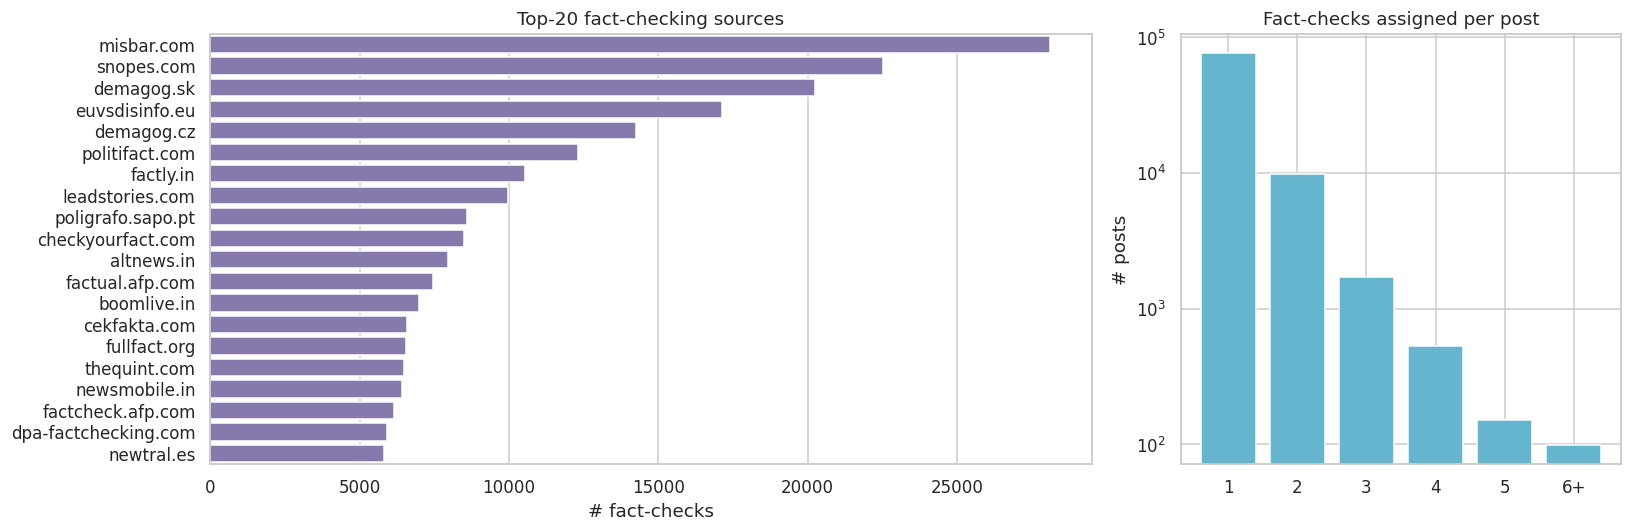

In [13]:
sources = collect_pd(spark.sql("""SELECT domain, FIRST(lang) AS main_lang, COUNT(*) AS n FROM fcs
                                   WHERE domain IS NOT NULL GROUP BY domain ORDER BY n DESC LIMIT 20"""))
fpp = collect_pd(spark.sql("""SELECT LEAST(k, 6) AS fact_checks_per_post, COUNT(*) AS posts
                              FROM (SELECT post_id, COUNT(*) AS k FROM pairs GROUP BY post_id) GROUP BY 1 ORDER BY 1"""))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
sns.barplot(data=sources, y="domain", x="n", ax=axes[0], color="#8172B3")
axes[0].set(title="Top-20 fact-checking sources", xlabel="# fact-checks", ylabel="")
axes[1].bar(fpp.fact_checks_per_post.astype(str).replace({"6": "6+"}), fpp.posts, color="#64B5CD")
axes[1].set(title="Fact-checks assigned per post", yscale="log", ylabel="# posts")
plt.tight_layout(); savefig("eda_sources")

**Key EDA take-aways** (they directly motivate the modelling choices below)
* The language distribution is extremely long-tailed for both posts and fact-checks, so scores are **macro-averaged per language** to stop English and Spanish from dominating.
* Crosslingual links are dominated by South- and East-Asian-language posts linked to English fact-checks (e.g. `eng-hin`, `eng-zho`, `eng-urd`). Lexical matching on original text cannot solve these by construction, which motivates translation and multilingual encoders (RQ1).
* Claims are short (median under 100 characters) while posts are long-tailed, so retrieval is **asymmetric**: short documents, long noisy queries.
* Most posts are linked to a single fact-check, so Success@K and Recall@K are nearly identical; Success@K is used as the headline metric.

## 6. Train / dev / test split and evaluation pool
* **Split:** posts are randomly split 80 / 10 / 10 % with a fixed seed. Because the split happens after de-duplication, no identical post text appears on both sides.
* **Retrieval pool:** in `full` mode every fact-check is a candidate. In `quick` mode the pool consists of every gold fact-check of the evaluated posts plus `n_distractor_fc` random fact-checks. Scores are then optimistic relative to the full pool, but all methods are compared on the identical pool.
* **Hard-negative pool:** used for fine-tuning only, it contains only fact-checks that are *not* gold for any dev/test post, so no evaluation label can leak into training.

In [14]:
posts = pd.read_parquet(PARQ_DIR / "posts")
fcs = pd.read_parquet(PARQ_DIR / "fact_checks")
pairs = pd.read_parquet(PARQ_DIR / "pairs")

def to_object_strings(df):
    """pandas>=3 stores text as Arrow strings; plain object arrays keep NumPy fancy-indexing working everywhere."""
    for c in df.columns:
        if df[c].dtype != object and pd.api.types.is_string_dtype(df[c].dtype):
            df[c] = df[c].astype(object)
    return df
posts, fcs, pairs = map(to_object_strings, (posts, fcs, pairs))

rng = np.random.default_rng(SEED)
perm = rng.permutation(np.sort(posts.post_id.values))
n_tr, n_dev = int(0.8 * len(perm)), int(0.1 * len(perm))
split_of = pd.Series("test", index=perm)
split_of.iloc[:n_tr] = "train"; split_of.iloc[n_tr:n_tr + n_dev] = "dev"
posts["split"] = posts.post_id.map(split_of)

pairs = (pairs.merge(posts[["post_id", "split", "lang"]].rename(columns={"lang": "post_lang"}), on="post_id")
              .merge(fcs[["fact_check_id", "lang"]].rename(columns={"lang": "fc_lang"}), on="fact_check_id"))
pairs["is_cross"] = pairs.post_lang != pairs.fc_lang
display(pairs.groupby("split").agg(posts=("post_id", "nunique"), pairs=("post_id", "size"),
                                   crosslingual_share=("is_cross", "mean")).round(3))

# ---- evaluation queries (test posts) and retrieval pool ----
test_ids = np.sort(posts.loc[posts.split == "test", "post_id"].values)
if CFG["n_eval_posts"] and CFG["n_eval_posts"] < len(test_ids):
    test_ids = np.sort(rng.choice(test_ids, CFG["n_eval_posts"], replace=False))
gold_eval = set(pairs.loc[pairs.post_id.isin(test_ids), "fact_check_id"])
if CFG["n_distractor_fc"] is None:
    POOL = fcs.copy()
else:
    others = fcs[~fcs.fact_check_id.isin(gold_eval)]
    POOL = pd.concat([fcs[fcs.fact_check_id.isin(gold_eval)],
                      others.sample(min(CFG["n_distractor_fc"], len(others)), random_state=SEED)])
POOL = POOL.sort_values("fact_check_id").reset_index(drop=True)
EQ = posts[posts.post_id.isin(test_ids)].sort_values("post_id").reset_index(drop=True)   # evaluation queries
FC_POS = pd.Series(np.arange(len(POOL)), index=POOL.fact_check_id.values)
Q_POS = pd.Series(np.arange(len(EQ)), index=EQ.post_id.values)

EP = pairs[pairs.post_id.isin(test_ids)].copy().reset_index(drop=True)                    # evaluation pairs
EP["q"] = EP.post_id.map(Q_POS).values
EP["d"] = EP.fact_check_id.map(FC_POS).values
POOL_LANG, Q_LANG = POOL.lang.to_numpy(dtype=object), EQ.lang.to_numpy(dtype=object)
POOL_SIG = hashlib.md5(POOL.fact_check_id.values.tobytes()).hexdigest()[:10]
QUERY_SIG = hashlib.md5(EQ.post_id.values.tobytes()).hexdigest()[:10]

# attributes used for the breakdown analyses in section 12.3
covid_re = re.compile(r"corona|covid|korona", re.IGNORECASE)
EQ["covid"] = EQ.text_en.str.contains(covid_re) | EQ.text_og.str.contains(covid_re)
EQ["len_og"] = EQ.text_og.str.len()
for c in ["covid", "verdict", "platform", "len_og", "year", "has_ocr"]:
    EP[c] = EQ[c].values[EP.q.values]
print(f"Eval posts: {len(EQ):,} | eval pairs: {len(EP):,} (crosslingual {EP.is_cross.mean():.1%}) | "
      f"pool: {len(POOL):,} fact-checks in {POOL.lang.nunique()} languages")

,posts,pairs,crosslingual_share
split,,,
dev,8844,10442,0.168
test,8845,10552,0.163
train,70754,83614,0.164


Eval posts: 3,000 | eval pairs: 3,574 (crosslingual 16.2%) | pool: 103,535 fact-checks in 90 languages


## 7. Evaluation methodology
* **Two ranked lists per post.** Each method returns, for every evaluation post, a top-100 list over the **full pool** and a top-100 list over the **same-language pool** (fact-checks in the post's language).
* **Language-aware protocol.** A *monolingual* link (post and fact-check in the same language) is scored on the same-language list. This simulates a fact-checking organisation that searches its own archive. A *crosslingual* link is scored on the full list, because the system must search across languages to find it.
* **Success@K (S@K):** the share of links whose fact-check appears in the top K, reported with **95 % Agresti–Coull** confidence intervals (reliable even for small groups and proportions near 0 or 1).
* **Macro averaging.** The headline monolingual score is the mean over languages, and the headline crosslingual score is the mean over *fact-check-language–post-language* combinations, with rare combinations pooled into *Other*. Only groups with at least `min_pairs_group` links are counted. Micro (link-level) averages are also reported.
* **Realistic setting.** Full pool with no language filter: S@K curve, post-level **MRR@100** and **nDCG@10**.
* **Same-language bias (SLB):** the share of top-10 full-pool results written in the post's language. It is a diagnostic: a high SLB means the system effectively ignores fact-checks in other languages.
* **Significance:** McNemar's exact test on paired per-link outcomes.

In [15]:
def agresti_coull(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan, np.nan)
    n_t = n + z ** 2
    p_t = (k + z ** 2 / 2) / n_t
    h = z * math.sqrt(p_t * (1 - p_t) / n_t)
    return (k / n, max(0.0, p_t - h), min(1.0, p_t + h))

def gold_ranks(rank_arr, q_idx, d_idx):
    """1-based rank of each gold document in its query's ranked list (inf if not retrieved)."""
    hit = rank_arr[q_idx] == d_idx[:, None]
    return np.where(hit.any(1), hit.argmax(1) + 1, np.inf)

def topk_rows(S, k):
    k = min(k, S.shape[1])
    idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
    part = np.take_along_axis(S, idx, 1)
    order = np.argsort(-part, axis=1, kind="stable")
    idx, part = np.take_along_axis(idx, order, 1), np.take_along_axis(part, order, 1)
    idx[~np.isfinite(part)] = -1
    out = np.full((S.shape[0], TOPK), -1, dtype=np.int64)
    out[:, :k] = idx
    return out

CROSS_GROUP = (EP.fc_lang + "-" + EP.post_lang)
_cg = CROSS_GROUP[EP.is_cross].value_counts()
CROSS_GROUP = CROSS_GROUP.where(CROSS_GROUP.map(_cg).fillna(0) >= CFG["min_pairs_group"], "Other")
_ml = EP.loc[~EP.is_cross, "post_lang"].value_counts()
MONO_LANGS = sorted(_ml[_ml >= CFG["min_pairs_group"]].index)
print(f"Monolingual languages reported: {len(MONO_LANGS)} | crosslingual groups: "
      f"{sorted(CROSS_GROUP[EP.is_cross].unique())}")

RESULTS = {}

def evaluate(name, rank_full, rank_lang, family, version, extra=None):
    q, d = EP.q.values, EP.d.values
    r_full, r_lang = gold_ranks(rank_full, q, d), gold_ranks(rank_lang, q, d)
    r_proto = np.where(EP.is_cross.values, r_full, r_lang)
    hit10 = r_proto <= 10
    mono, cross = ~EP.is_cross.values, EP.is_cross.values
    per_lang = pd.Series(hit10[mono]).groupby(EP.post_lang.values[mono]).mean().reindex(MONO_LANGS)
    per_cross = pd.Series(hit10[cross]).groupby(CROSS_GROUP.values[cross]).mean()
    s_mono, lo_m, hi_m = agresti_coull(hit10[mono].sum(), mono.sum())
    s_cross, lo_c, hi_c = agresti_coull(hit10[cross].sum(), cross.sum())
    # realistic full-pool, post-level metrics
    df_r = pd.DataFrame({"q": q, "r": r_full})
    best = df_r.groupby("q").r.min()
    mrr = float((1.0 / best).mean())
    dcg = df_r.assign(g=np.where(df_r.r <= 10, 1 / np.log2(df_r.r + 1), 0)).groupby("q").g.sum()
    n_gold = df_r.groupby("q").size().clip(upper=10)
    idcg = n_gold.map(lambda n: sum(1 / math.log2(i + 2) for i in range(n)))
    top10 = rank_full[:, :10]
    slb = float(np.mean([(POOL_LANG[row[row >= 0]] == Q_LANG[i]).mean() for i, row in enumerate(top10)]))
    m = {"method": name, "family": family, "version": version,
         "mono_S@10_macro": per_lang.mean(), "cross_S@10_macro": per_cross.mean(),
         "mono_S@10_micro": s_mono, "mono_CI": f"[{lo_m:.3f}, {hi_m:.3f}]",
         "cross_S@10_micro": s_cross, "cross_CI": f"[{lo_c:.3f}, {hi_c:.3f}]",
         "all_S@10_fullpool": float((r_full <= 10).mean()), "MRR@100": mrr,
         "nDCG@10": float((dcg / idcg).mean()), "post_S@10_fullpool": float((best <= 10).mean()), "SLB": slb}
    m.update(extra or {})
    RESULTS[name] = {"metrics": m, "r_proto": r_proto, "r_full": r_full, "rank_full": rank_full,
                     "rank_lang": rank_lang, "per_lang": per_lang, "per_cross": per_cross}
    print(f"{name:52s} mono {per_lang.mean():.3f} | cross {per_cross.mean():.3f} | "
          f"full-pool S@10 {m['all_S@10_fullpool']:.3f} | MRR {mrr:.3f} | SLB {slb:.2f}")
    return m

Monolingual languages reported: 16 | crosslingual groups: ['Other', 'eng-hin']


## 8. BM25 baselines
### 8.1 Exact, vectorised BM25
Instead of looping over documents (as e.g. `rank_bm25` does, which is infeasible for 435k documents × thousands of queries), the BM25 term weights are pre-computed into a sparse document–term matrix **W** once, and a batch of queries is scored with a single sparse matrix product `Q · Wᵀ`:

$$\text{score}(q,d)=\sum_{t\in q} \text{qtf}_t\cdot\underbrace{\log\!\Big(1+\tfrac{N-df_t+0.5}{df_t+0.5}\Big)}_{\text{idf}_t}\cdot\frac{tf_{t,d}(k_1+1)}{tf_{t,d}+k_1\big(1-b+b\,\tfrac{|d|}{\text{avgdl}}\big)}$$

with the standard settings $k_1 = 1.2$, $b = 0.75$.
* **BM25-Original** — Unicode word tokenisation of the original texts (one multilingual index, no stemming, because no single stemmer covers 100+ languages).
* **BM25-English** — machine-translated texts with English stop-word removal and Porter stemming (a standard English IR pipeline).

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer

TOKEN_RE = re.compile(r"\w+", re.UNICODE)
_porter = PorterStemmer()
_stem = functools.lru_cache(maxsize=1_000_000)(_porter.stem)

def tok_og(text):
    return TOKEN_RE.findall(text.lower())

def tok_en(text):
    return [_stem(t) for t in TOKEN_RE.findall(text.lower()) if t not in ENGLISH_STOP_WORDS and len(t) > 1]

class SparseBM25:
    def __init__(self, tokenizer, k1=BM25_K1, b=BM25_B):
        self.tokenizer, self.k1, self.b = tokenizer, k1, b

    def fit(self, docs):
        self.vec = CountVectorizer(tokenizer=self.tokenizer, lowercase=False, token_pattern=None, dtype=np.float32)
        tf = self.vec.fit_transform(docs).tocsr()
        N = tf.shape[0]
        dl = np.asarray(tf.sum(1)).ravel()
        avgdl = dl.mean()
        df = np.bincount(tf.indices, minlength=tf.shape[1])
        self.idf = np.log1p((N - df + 0.5) / (df + 0.5)).astype(np.float32)
        rows = np.repeat(np.arange(N), np.diff(tf.indptr))
        t = tf.data
        tf.data = self.idf[tf.indices] * t * (self.k1 + 1) / (t + self.k1 * (1 - self.b + self.b * dl[rows] / avgdl))
        self.WT = tf.T.tocsr().astype(np.float32)          # vocabulary x documents
        return self

    def scores(self, queries):
        return (self.vec.transform(queries).astype(np.float32) @ self.WT).toarray()

    def search(self, queries, k=TOPK, q_langs=None, doc_langs=None, batch=64):
        """Returns top-k over the full pool and (optionally) over the same-language pool."""
        nq = len(queries)
        full = np.full((nq, TOPK), -1, dtype=np.int64)
        lang = np.full((nq, TOPK), -1, dtype=np.int64) if q_langs is not None else None
        for s in range(0, nq, batch):
            S = self.scores(queries[s:s + batch])
            full[s:s + batch] = topk_rows(S, k)
            if q_langs is not None:
                S[doc_langs[None, :] != np.asarray(q_langs[s:s + batch])[:, None]] = -np.inf
                lang[s:s + batch] = topk_rows(S, k)
        return full, lang

BM25_INDEX = {}
for version, tok in [("og", tok_og), ("en", tok_en)]:
    docs = POOL[f"claim_{version}"].tolist()
    queries = EQ[f"text_{version}"].tolist()
    with timer(f"bm25_{version}_index"):
        BM25_INDEX[version] = SparseBM25(tok).fit(docs)
    with timer(f"bm25_{version}_search"):
        rf, rl = BM25_INDEX[version].search(queries, q_langs=Q_LANG, doc_langs=POOL_LANG)
    evaluate(f"BM25-{'Original' if version == 'og' else 'English'}", rf, rl, "BM25", version,
             extra={"index_s": TIMINGS[f"bm25_{version}_index"],
                    "ms_per_query": 1000 * TIMINGS[f"bm25_{version}_search"] / len(queries) / 2})
    print(f"   vocabulary: {len(BM25_INDEX[version].idf):,} terms")

[time] bm25_og_index: 2.6s
[time] bm25_og_search: 12.9s
BM25-Original                                        mono 0.641 | cross 0.107 | full-pool S@10 0.558 | MRR 0.508 | SLB 0.89
   vocabulary: 223,087 terms
[time] bm25_en_index: 3.2s
[time] bm25_en_search: 12.0s
BM25-English                                         mono 0.836 | cross 0.580 | full-pool S@10 0.693 | MRR 0.570 | SLB 0.31
   vocabulary: 45,385 terms


### 8.2 Distributed BM25 with a Spark inverted index
To demonstrate how lexical retrieval scales out beyond a single machine's memory, the BM25-English index is also built as a **distributed inverted index** in Spark: documents are tokenised by a UDF, term frequencies, document frequencies and document lengths are computed with `groupBy` aggregations, and the final per-posting BM25 weights are persisted as Parquet. Queries are scored with a distributed join on the term column followed by a windowed top-k.

Very frequent terms (document frequency > `spark_bm25_max_df` of the pool) are pruned from the query side to bound the size of the join — a standard *impact-pruning* trade-off in large-scale IR. The cell measures how much this changes the ranking compared with the exact single-node implementation.

In [17]:
from pyspark.sql.types import LongType
def tok_en_spark(text):
    """Same tokens as tok_en, without the driver-side LRU cache (which cannot be shipped to Spark workers)."""
    return [_porter.stem(t) for t in TOKEN_RE.findall((text or "").lower()) if t not in ENGLISH_STOP_WORDS and len(t) > 1]
tok_en_udf = F.udf(tok_en_spark, ArrayType(StringType()))
SBM = WORK_DIR / "spark_bm25"
pd.DataFrame({"d": np.arange(len(POOL), dtype=np.int64), "text": POOL.claim_en.values}).to_parquet(SBM / "docs.parquet")
nq_spark = min(CFG["spark_bm25_queries"], len(EQ))
pd.DataFrame({"q": np.arange(nq_spark, dtype=np.int64), "text": EQ.text_en.values[:nq_spark]}).to_parquet(SBM / "queries.parquet")

with timer("spark_bm25_index"):
    docs_s = spark.read.parquet(str(SBM / "docs.parquet")).repartition(16)
    tf_s = (docs_s.select("d", F.explode(tok_en_udf("text")).alias("term"))
                  .groupBy("d", "term").agg(F.count("*").alias("tf")))
    dl_s = tf_s.groupBy("d").agg(F.sum("tf").alias("dl"))
    N_docs = docs_s.count()
    avgdl = dl_s.agg(F.avg("dl")).first()[0]
    df_s = (tf_s.groupBy("term").agg(F.count("*").alias("df"))
                .withColumn("idf", F.log1p((F.lit(N_docs) - F.col("df") + 0.5) / (F.col("df") + 0.5))))
    postings = (tf_s.join(dl_s, "d").join(df_s, "term")
                    .withColumn("w", F.col("idf") * F.col("tf") * (BM25_K1 + 1) /
                                (F.col("tf") + BM25_K1 * (1 - BM25_B + BM25_B * F.col("dl") / F.lit(avgdl))))
                    .select("term", "d", "w", "df"))
    postings.write.mode("overwrite").parquet(str(SBM / "inverted_index"))

with timer("spark_bm25_search"):
    index_s = spark.read.parquet(str(SBM / "inverted_index"))
    q_terms = (spark.read.parquet(str(SBM / "queries.parquet"))
                    .select("q", F.explode(tok_en_udf("text")).alias("term"))
                    .groupBy("q", "term").agg(F.count("*").alias("qtf")))
    pruned = index_s.filter(F.col("df") <= CFG["spark_bm25_max_df"] * N_docs)
    scores_s = (q_terms.join(pruned, "term")
                       .groupBy("q", "d").agg(F.sum(F.col("qtf") * F.col("w")).alias("score")))
    win = Window.partitionBy("q").orderBy(F.desc("score"), F.asc("d"))
    top_s = collect_pd(scores_s.withColumn("r", F.row_number().over(win)).filter("r <= 10"))

print(f"Inverted index: {index_s.count():,} postings, {df_s.count():,} terms, avgdl={avgdl:.1f}")
spark_rank = np.full((nq_spark, 10), -1)
for row in top_s.itertuples():
    spark_rank[row.q, row.r - 1] = row.d
exact_rank = RESULTS["BM25-English"]["rank_full"][:nq_spark, :10]
overlap = np.mean([len(set(a[a >= 0]) & set(b[b >= 0])) / 10 for a, b in zip(spark_rank, exact_rank)])
sel = EP.q.values < nq_spark
sp_hit = (gold_ranks(np.pad(spark_rank, ((0, 0), (0, TOPK - 10)), constant_values=-1), EP.q.values[sel], EP.d.values[sel]) <= 10).mean()
ex_hit = (RESULTS["BM25-English"]["r_full"][sel] <= 10).mean()
print(f"Top-10 overlap Spark (pruned) vs exact: {overlap:.3f} | full-pool S@10 on {nq_spark} queries: "
      f"Spark {sp_hit:.3f} vs exact {ex_hit:.3f}")

[time] spark_bm25_index: 87.1s
[time] spark_bm25_search: 18.4s
Inverted index: 1,081,453 postings, 45,385 terms, avgdl=11.1
Top-10 overlap Spark (pruned) vs exact: 0.966 | full-pool S@10 on 300 queries: Spark 0.648 vs exact 0.648


## 9. Semantic retrieval: SentenceTransformers + FAISS
Posts and fact-check claims are embedded into a shared vector space by bi-encoder sentence-embedding models. Embeddings are L2-normalised, so the inner product equals cosine similarity, and the pool is indexed with an exact **FAISS `IndexFlatIP`**. For the monolingual protocol, per-language sub-indices are built on the fly.

* *English encoders* run on the **English (machine-translated)** version.
* *Multilingual encoders* run on both the **original** and the **English** version, which isolates the effect of translation (RQ1).

Embeddings are cached to `WORK_DIR/emb`, keyed by model (including a fingerprint of fine-tuned weights), dataset version and a hash of the pool / query ids.

In [18]:
import faiss
from sentence_transformers import SentenceTransformer

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")[-60:]

def load_encoder(name_or_path):
    model = SentenceTransformer(str(name_or_path), device=DEVICE)
    if CFG["max_seq_length"]:
        model.max_seq_length = min(model.max_seq_length or 512, CFG["max_seq_length"])
    return model

def encode(model, texts, key):
    path = EMB_DIR / f"{key}.npy"
    if path.exists():
        return np.load(path)
    E = model.encode(list(texts), batch_size=CFG["encode_batch_size"], normalize_embeddings=True,
                     convert_to_numpy=True, show_progress_bar=True).astype(np.float32)
    np.save(path, E)
    return E

def faiss_search(q_emb, d_emb, k=TOPK):
    index = faiss.IndexFlatIP(d_emb.shape[1])
    index.add(d_emb)
    t0 = time.perf_counter()
    _, I_full = index.search(q_emb, k)
    ms = 1000 * (time.perf_counter() - t0) / len(q_emb)
    I_lang = np.full_like(I_full, -1)
    for lg in np.unique(Q_LANG):
        qm, dm = np.where(Q_LANG == lg)[0], np.where(POOL_LANG == lg)[0]
        if len(dm) == 0:
            continue
        sub = faiss.IndexFlatIP(d_emb.shape[1]); sub.add(d_emb[dm])
        kk = min(k, len(dm))
        _, I = sub.search(q_emb[qm], kk)
        I_lang[qm, :kk] = dm[I]
    return I_full.astype(np.int64), I_lang.astype(np.int64), ms

EMB_KEYS = {}   # method label -> (query-embedding key, pool-embedding key)

def model_fingerprint(model_name):
    """Local (fine-tuned) models get a fingerprint of their weight files, so re-training invalidates cached embeddings."""
    p = Path(str(model_name))
    if not p.exists():
        return slug(model_name)
    stats = sorted((f.name, f.stat().st_size, int(f.stat().st_mtime)) for f in p.rglob("*") if f.is_file())
    return slug(model_name) + "_" + hashlib.md5(repr(stats).encode()).hexdigest()[:8]

def run_dense(label, model_name, version, family, model=None):
    tag = model_fingerprint(model_name)
    qk, dk = f"{tag}_{version}_q{QUERY_SIG}", f"{tag}_{version}_p{POOL_SIG}"
    t0 = time.perf_counter()
    if model is None and not ((EMB_DIR / f"{qk}.npy").exists() and (EMB_DIR / f"{dk}.npy").exists()):
        model = load_encoder(model_name)
    D = encode(model, POOL[f"claim_{version}"].values, dk)
    Q = encode(model, EQ[f"text_{version}"].values, qk)
    enc_s = time.perf_counter() - t0
    rf, rl, ms = faiss_search(Q, D)
    EMB_KEYS[label] = (qk, dk)
    evaluate(label, rf, rl, family, version, extra={"index_s": enc_s, "ms_per_query": ms, "model": str(model_name)})
    del model; gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

with timer("dense_unsupervised"):
    for label, name, version in CFG["dense_models"]:
        family = "Multilingual encoder" if ("multilingual" in name.lower() or "labse" in name.lower()) else "English encoder"
        run_dense(label, name, version, family)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (26 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/809 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Multi-MiniLM-L12 (En)                                mono 0.780 | cross 0.489 | full-pool S@10 0.616 | MRR 0.482 | SLB 0.28
[time] dense_unsupervised: 332.2s


## 10. Hybrid retrieval — Reciprocal Rank Fusion
BM25 and embedding models fail on different posts: BM25 catches exact names, numbers and rare terms, while embeddings catch paraphrases. **RRF** combines ranked lists without calibrating their scores: $\text{RRF}(d)=\sum_{m} 1/(60+\text{rank}_m(d))$. Fusion is applied to both the full-pool and the same-language lists (RQ2).

In [19]:
def rrf(rank_lists, c=60, k=TOPK):
    nq = rank_lists[0].shape[0]
    out = np.full((nq, k), -1, dtype=np.int64)
    for i in range(nq):
        sc = defaultdict(float)
        for R in rank_lists:
            for r, d in enumerate(R[i]):
                if d < 0:
                    break
                sc[d] += 1.0 / (c + r + 1)
        best = sorted(sc.items(), key=lambda x: -x[1])[:k]
        out[i, :len(best)] = [d for d, _ in best]
    return out

def fuse(label, members):
    rf = rrf([RESULTS[m]["rank_full"] for m in members])
    rl = rrf([RESULTS[m]["rank_lang"] for m in members])
    evaluate(label, rf, rl, "Hybrid (RRF)", "+".join(sorted({RESULTS[m]["metrics"]["version"] for m in members})),
             extra={"members": " + ".join(members)})

def overall(name):
    m = RESULTS[name]["metrics"]
    return m["mono_S@10_macro"] + m["cross_S@10_macro"]

dense_names = [k for k, v in RESULTS.items() if "encoder" in v["metrics"]["family"]]
best_en = max([n for n in dense_names if RESULTS[n]["metrics"]["version"] == "en"], key=overall)
best_og = max([n for n in dense_names if RESULTS[n]["metrics"]["version"] == "og"], key=overall)
fuse(f"RRF: BM25-En + {best_en}", ["BM25-English", best_en])
fuse(f"RRF: BM25-En + {best_en} + {best_og}", ["BM25-English", best_en, best_og])

RRF: BM25-En + MiniLM-L12 (En)                       mono 0.868 | cross 0.666 | full-pool S@10 0.764 | MRR 0.606 | SLB 0.33
RRF: BM25-En + MiniLM-L12 (En) + Multi-MiniLM-L12 (Og) mono 0.865 | cross 0.652 | full-pool S@10 0.762 | MRR 0.591 | SLB 0.34


## 11. Supervised fine-tuning: random vs hard negatives (RQ3)
Off-the-shelf encoders are trained on generic paraphrase data, not on the post → fact-check relation. Two training recipes are compared. Both use only the **train split** and are evaluated on the same test posts.

1. **Baseline — online-contrastive loss with random negatives.** Positive pairs are the (post, fact-check) links; negatives are random (post, fact-check) combinations, with positives making up 30 % of the samples and a margin of 0.4. This is the classic Siamese set-up. *Hypothesis:* random negatives are almost always topically unrelated, so they are too easy and the model stops learning early.
2. **Proposed — Multiple-Negatives-Ranking loss (InfoNCE) with BM25-mined hard negatives.** Every other fact-check in the batch acts as a negative, and each example also carries one *hard* negative: a lexically similar but wrong fact-check, sampled from BM25-English ranks 3–30 over a training-side pool. The model must therefore learn *which* similar-looking claim is the right one.
   * **False-negative control:** several organisations often check the same claim, so the top BM25 hits may be valid but unlabelled matches. Ranks 1–2 are skipped and exact duplicates of the gold claim are excluded.
   * A no-duplicates batch sampler stops the same claim from appearing twice in a batch, which would otherwise create a false in-batch negative.

In [20]:
from datasets import Dataset
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers

train_pairs = pairs[pairs.split == "train"]
if CFG["ft_max_train_pairs"] and len(train_pairs) > CFG["ft_max_train_pairs"]:
    train_pairs = train_pairs.sample(CFG["ft_max_train_pairs"], random_state=SEED)
train_pairs = train_pairs.reset_index(drop=True)
post_text = posts.set_index("post_id")[["text_og", "text_en"]]
fc_text = fcs.set_index("fact_check_id")[["claim_og", "claim_en"]]
gold_of = pairs.groupby("post_id").fact_check_id.agg(set)
print(f"Training pairs: {len(train_pairs):,} from {train_pairs.post_id.nunique():,} train posts")

# ---- hard-negative mining with BM25-English over a training-side fact-check pool ----
heldout_gold = set(pairs.loc[pairs.split != "train", "fact_check_id"])
hn_pool = fcs[~fcs.fact_check_id.isin(heldout_gold)]
if CFG["hardneg_pool_size"] and len(hn_pool) > CFG["hardneg_pool_size"]:
    hn_pool = pd.concat([hn_pool[hn_pool.fact_check_id.isin(set(train_pairs.fact_check_id))],
                         hn_pool.sample(CFG["hardneg_pool_size"], random_state=SEED)]).drop_duplicates("fact_check_id")
hn_pool = hn_pool.reset_index(drop=True)
with timer("hardneg_mining"):
    bm_hn = SparseBM25(tok_en).fit(hn_pool.claim_en.tolist())
    uniq_posts = train_pairs.post_id.unique()
    cand, _ = bm_hn.search(post_text.loc[uniq_posts, "text_en"].tolist(), k=30)
hn_ids = hn_pool.fact_check_id.values
cand_of = dict(zip(uniq_posts, cand))
rng_hn = np.random.default_rng(SEED)

def pick_hard_negative(post_id, gold_fc):
    golds = gold_of[post_id]
    gold_claims = {fc_text.at[g, "claim_en"].lower() for g in golds}
    options = [hn_ids[i] for i in cand_of[post_id][2:30] if i >= 0 and hn_ids[i] not in golds
               and fc_text.at[hn_ids[i], "claim_en"].lower() not in gold_claims]
    if not options:
        options = [x for x in rng_hn.choice(hn_ids, 5) if x not in golds]
    return options[rng_hn.integers(len(options))]

train_pairs["hard_neg"] = [pick_hard_negative(p, f) for p, f in zip(train_pairs.post_id, train_pairs.fact_check_id)]
ex = train_pairs.sample(3, random_state=1)
for r in ex.itertuples():
    print(f"\nPOST     : {post_text.at[r.post_id, 'text_en'][:150]}\nGOLD     : {fc_text.at[r.fact_check_id, 'claim_en']}"
          f"\nHARD NEG : {fc_text.at[r.hard_neg, 'claim_en']}")

Training pairs: 20,000 from 19,150 train posts
[time] hardneg_mining: 25.0s

POST     : Australian system pigs beating up a crippled black c0vid tyranny protester.
GOLD     : This video shows Australian police officers arresting protesters against COVID-19 lockdown measures.
HARD NEG : Police beat a man in Australia in protest against confinement

POST     : ✏The revenge continues: 👉His Excellency Abune Abraham&#39;s passport has been seized to prevent him from leaving the country, 👉Although his name was i
GOLD     : Ethiopian officials prevent church leader’s trip to SA
HARD NEG : In South Africa it is raining from the sky at the same place

POST     : &quot;They&#39;re shutting down the food supply worldwide. They are culling the livestock. They are buying up and shutting down the farmlands.&quot; &
GOLD     : They are shutting down the food supply around the world. They destroy livestock. They buy and close the agricultural lands. They say that to meet our carbon targets we will des

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


Step,Training Loss
50,0.951463
100,0.674414
150,0.347549
200,0.241728
250,0.140860
300,0.149996
350,0.151159
400,0.164402
450,0.147376
500,0.096462


FT Multi-MiniLM (Og) · RandomNeg [baseline]: 66,667 examples, 385s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/809 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

FT MiniLM-L12 (En) · MNRL+HardNeg [proposed]         mono 0.887 | cross 0.730 | full-pool S@10 0.791 | MRR 0.644 | SLB 0.33
[time] finetuning: 838.8s


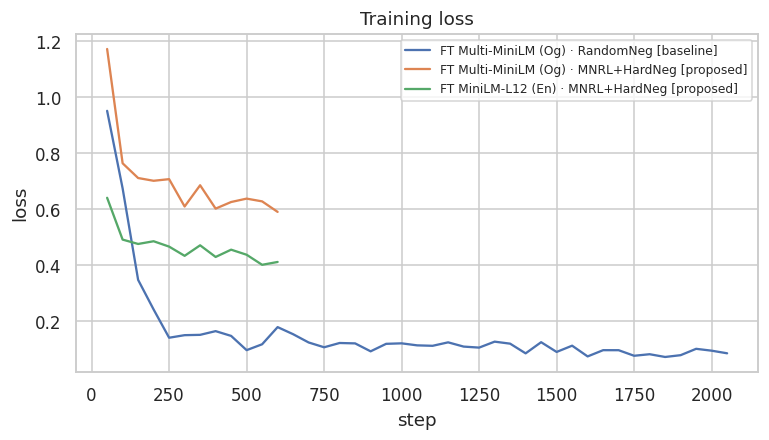

In [21]:
def build_dataset(loss_kind, version):
    P = post_text.loc[train_pairs.post_id, f"text_{version}"].values
    G = fc_text.loc[train_pairs.fact_check_id, f"claim_{version}"].values
    if loss_kind == "mnrl":
        H = fc_text.loc[train_pairs.hard_neg, f"claim_{version}"].values
        return Dataset.from_dict({"anchor": list(P), "positive": list(G), "negative": list(H)})
    # online-contrastive: positives + random negatives (positives = OCL_POS_RATIO of all samples)
    n_neg = int(round(len(P) * (1 - OCL_POS_RATIO) / OCL_POS_RATIO))
    r = np.random.default_rng(SEED)
    neg_posts = r.choice(train_pairs.post_id.values, n_neg)
    neg_fcs = r.choice(fcs.fact_check_id.values, n_neg)
    keep = np.array([f not in gold_of[p] for p, f in zip(neg_posts, neg_fcs)])
    neg_posts, neg_fcs = neg_posts[keep], neg_fcs[keep]
    s1 = list(P) + list(post_text.loc[neg_posts, f"text_{version}"].values)
    s2 = list(G) + list(fc_text.loc[neg_fcs, f"claim_{version}"].values)
    y = [1] * len(P) + [0] * len(neg_posts)
    return Dataset.from_dict({"sentence1": s1, "sentence2": s2, "label": y}).shuffle(seed=SEED)

def finetune(label, base, version, loss_kind, lr):
    out_dir = MODEL_DIR / slug(label)
    if (out_dir / "modules.json").exists():          # delete the folder to retrain after changing settings
        print(f"Re-using fine-tuned model in {out_dir}")
        return load_encoder(out_dir), out_dir
    model = load_encoder(base)
    ds = build_dataset(loss_kind, version)
    loss = (losses.MultipleNegativesRankingLoss(model) if loss_kind == "mnrl"
            else losses.OnlineContrastiveLoss(model, margin=OCL_MARGIN))
    use_fp16 = DEVICE == "cuda" and "t5" not in str(base).lower()     # T5 models are numerically unstable in fp16
    use_bf16 = DEVICE == "cuda" and "t5" in str(base).lower() and torch.cuda.is_bf16_supported()
    args = SentenceTransformerTrainingArguments(
        output_dir=str(out_dir / "_ckpt"), num_train_epochs=CFG["ft_epochs"],
        per_device_train_batch_size=CFG["ft_batch_size"], learning_rate=lr, warmup_ratio=0.1,
        lr_scheduler_type="cosine", weight_decay=1e-5, fp16=use_fp16, bf16=use_bf16,
        batch_sampler=BatchSamplers.NO_DUPLICATES if loss_kind == "mnrl" else BatchSamplers.BATCH_SAMPLER,
        save_strategy="no", logging_steps=50, report_to="none", seed=SEED)
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=ds, loss=loss)
    t0 = time.perf_counter()
    trainer.train()
    print(f"{label}: {len(ds):,} examples, {time.perf_counter() - t0:.0f}s")
    model.save(str(out_dir))
    shutil.rmtree(out_dir / "_ckpt", ignore_errors=True)
    hist = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
    if len(hist):
        hist.to_csv(RES_DIR / f"trainlog_{slug(label)}.csv", index=False)
    return model, out_dir

FT_LOGS = {}
with timer("finetuning"):
    for label, base, version, loss_kind, lr in CFG["ft_jobs"]:
        model, path = finetune(label, base, version, loss_kind, lr)
        run_dense(label, path, version, "Fine-tuned encoder", model=model)
        log = RES_DIR / f"trainlog_{slug(label)}.csv"
        if log.exists():
            FT_LOGS[label] = pd.read_csv(log)

if FT_LOGS:
    plt.figure(figsize=(8, 4))
    for k_, h in FT_LOGS.items():
        plt.plot(h["step"], h["loss"], label=k_)
    plt.title("Training loss"); plt.xlabel("step"); plt.ylabel("loss"); plt.legend(fontsize=8)
    savefig("training_loss")

## 12. Results and breakdown analyses
### 12.1 Main results table

In [22]:
res = pd.DataFrame([v["metrics"] for v in RESULTS.values()]).set_index("method")
main_cols = ["family", "version", "mono_S@10_macro", "cross_S@10_macro", "mono_S@10_micro", "mono_CI",
             "cross_S@10_micro", "cross_CI", "all_S@10_fullpool", "post_S@10_fullpool", "MRR@100", "nDCG@10", "SLB",
             "index_s", "ms_per_query"]
main = res[[c for c in main_cols if c in res]].sort_values("mono_S@10_macro", ascending=False)
res.to_csv(RES_DIR / "results_main.csv")
num = main.select_dtypes("number").columns
display(main.style.format({c: "{:.3f}" for c in num} | {"index_s": "{:.0f}", "ms_per_query": "{:.2f}"})
        .background_gradient(subset=["mono_S@10_macro", "cross_S@10_macro", "MRR@100"], cmap="Greens"))

,family,version,mono_S@10_macro,cross_S@10_macro,mono_S@10_micro,mono_CI,cross_S@10_micro,cross_CI,all_S@10_fullpool,post_S@10_fullpool,MRR@100,nDCG@10,SLB,index_s,ms_per_query
method,,,,,,,,,,,,,,,
FT MiniLM-L12 (En) · MNRL+HardNeg [proposed],Fine-tuned encoder,en,0.887,0.730,0.878,"[0.865, 0.889]",0.727,"[0.689, 0.761]",0.791,0.810,0.644,0.672,0.334,41,1.23
RRF: BM25-En + MiniLM-L12 (En),Hybrid (RRF),en,0.868,0.666,0.857,"[0.844, 0.869]",0.659,"[0.620, 0.697]",0.764,0.788,0.606,0.635,0.333,nan,nan
RRF: BM25-En + MiniLM-L12 (En) + Multi-MiniLM-L12 (Og),Hybrid (RRF),en+og,0.865,0.652,0.852,"[0.839, 0.864]",0.647,"[0.607, 0.685]",0.762,0.781,0.591,0.622,0.339,nan,nan
MiniLM-L12 (En),English encoder,en,0.839,0.616,0.824,"[0.810, 0.838]",0.618,"[0.577, 0.656]",0.699,0.724,0.553,0.579,0.312,90,0.80
BM25-English,BM25,en,0.836,0.580,0.815,"[0.801, 0.829]",0.574,"[0.534, 0.614]",0.693,0.721,0.570,0.590,0.313,3,1.99
FT Multi-MiniLM (Og) · MNRL+HardNeg [proposed],Fine-tuned encoder,og,0.809,0.483,0.809,"[0.795, 0.823]",0.484,"[0.444, 0.525]",0.679,0.703,0.566,0.583,0.348,51,0.78
Multi-MiniLM-L12 (En),Multilingual encoder,en,0.780,0.489,0.759,"[0.743, 0.774]",0.503,"[0.463, 0.544]",0.616,0.637,0.482,0.503,0.278,99,0.75
FT Multi-MiniLM (Og) · RandomNeg [baseline],Fine-tuned encoder,og,0.777,0.405,0.775,"[0.760, 0.790]",0.415,"[0.376, 0.456]",0.638,0.665,0.528,0.544,0.373,50,0.80
BM25-Original,BM25,og,0.641,0.107,0.653,"[0.636, 0.670]",0.130,"[0.105, 0.160]",0.558,0.597,0.508,0.510,0.895,3,2.15


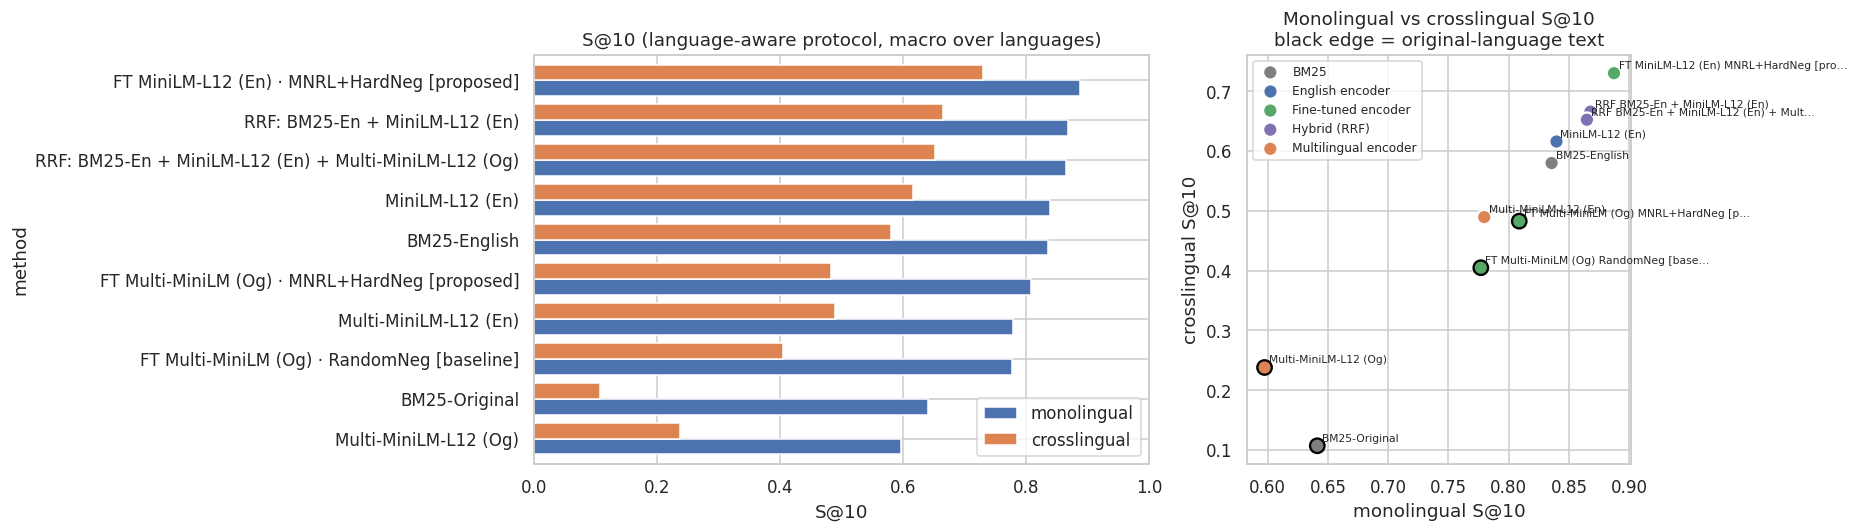

In [23]:
order = main.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(17, max(5, 0.42 * len(order))), gridspec_kw={"width_ratios": [1.6, 1]})
plot_df = main[["mono_S@10_macro", "cross_S@10_macro"]].rename(columns=lambda c: c.split("_")[0])
plot_df.iloc[::-1].plot.barh(ax=axes[0], color=["#4C72B0", "#DD8452"], width=0.8)
axes[0].set(title="S@10 (language-aware protocol, macro over languages)", xlabel="S@10", xlim=(0, 1))
axes[0].legend(["monolingual", "crosslingual"], loc="lower right")

palette = {"BM25": "#7F7F7F", "English encoder": "#4C72B0", "Multilingual encoder": "#DD8452",
           "Fine-tuned encoder": "#55A868", "Hybrid (RRF)": "#8172B3"}
for fam, g in main.groupby("family"):
    axes[1].scatter(g["mono_S@10_macro"], g["cross_S@10_macro"], s=90, label=fam, color=palette.get(fam),
                    edgecolor=["black" if v == "og" else "white" for v in g.version], linewidth=1.5)
for n, r in main.iterrows():
    short = n.replace(" · ", " ").replace("RRF: ", "RRF ")
    axes[1].annotate(short if len(short) <= 38 else short[:36] + "…", (r["mono_S@10_macro"], r["cross_S@10_macro"]), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set(title="Monolingual vs crosslingual S@10\nblack edge = original-language text",
            xlabel="monolingual S@10", ylabel="crosslingual S@10")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("results_main")

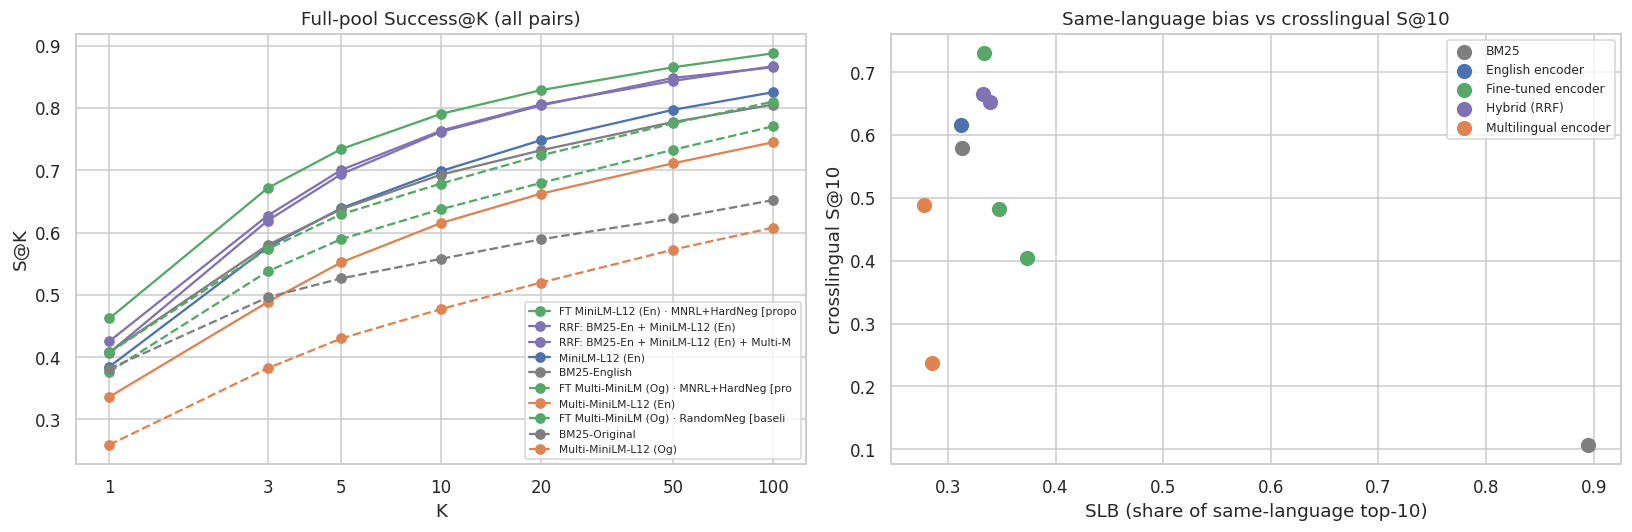

In [24]:
# Success@K curves on the full pool (no language filter) + same-language bias vs crosslingual performance
Ks = [1, 3, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n in order:
    rf_ = RESULTS[n]["r_full"]
    axes[0].plot(Ks, [(rf_ <= k).mean() for k in Ks], marker="o", label=n[:40],
                 color=palette.get(RESULTS[n]["metrics"]["family"]),
                 linestyle="--" if RESULTS[n]["metrics"]["version"] == "og" else "-")
axes[0].set(xscale="log", xticks=Ks, xticklabels=Ks, title="Full-pool Success@K (all pairs)", xlabel="K", ylabel="S@K")
axes[0].legend(fontsize=7)
for fam, g in main.groupby("family"):
    axes[1].scatter(g["SLB"], g["cross_S@10_macro"], label=fam, s=80, color=palette.get(fam))
axes[1].set(title="Same-language bias vs crosslingual S@10", xlabel="SLB (share of same-language top-10)",
            ylabel="crosslingual S@10")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("results_sk_slb")

### 12.2 Per-language performance

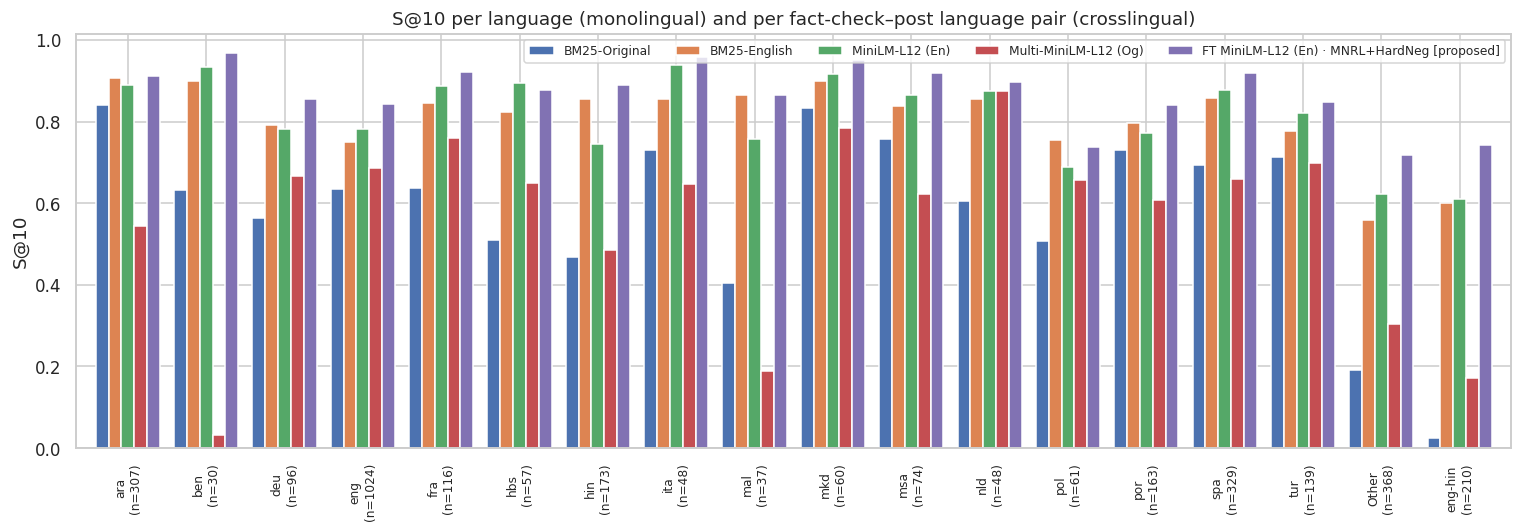

In [25]:
unsup = [n for n in order if RESULTS[n]["metrics"]["family"] in ("BM25", "English encoder", "Multilingual encoder")]
selected = [n for n in ["BM25-Original", "BM25-English", best_en, best_og] if n in RESULTS]
ft_names = [n for n in order if RESULTS[n]["metrics"]["family"] == "Fine-tuned encoder"]
if ft_names:
    selected.append(max(ft_names, key=overall))
selected = list(dict.fromkeys(selected))

per = pd.DataFrame({n: pd.concat([RESULTS[n]["per_lang"], RESULTS[n]["per_cross"]]) for n in selected})
counts = pd.concat([EP[~EP.is_cross].post_lang.value_counts(), CROSS_GROUP[EP.is_cross].value_counts()])
per = per.loc[[i for i in per.index if i in counts.index]]
per.index = [f"{i}\n(n={counts[i]})" for i in per.index]
per.to_csv(RES_DIR / "results_per_language.csv")
fig, ax = plt.subplots(figsize=(max(14, 0.55 * len(per)), 5))
per.plot.bar(ax=ax, width=0.82)
ax.set(title="S@10 per language (monolingual) and per fact-check–post language pair (crosslingual)", ylabel="S@10")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(fontsize=8, ncol=len(selected))
plt.tight_layout(); savefig("results_per_language")

### 12.3 Breakdowns: COVID-19, post rating, platform, OCR, post length and time (RQ4)

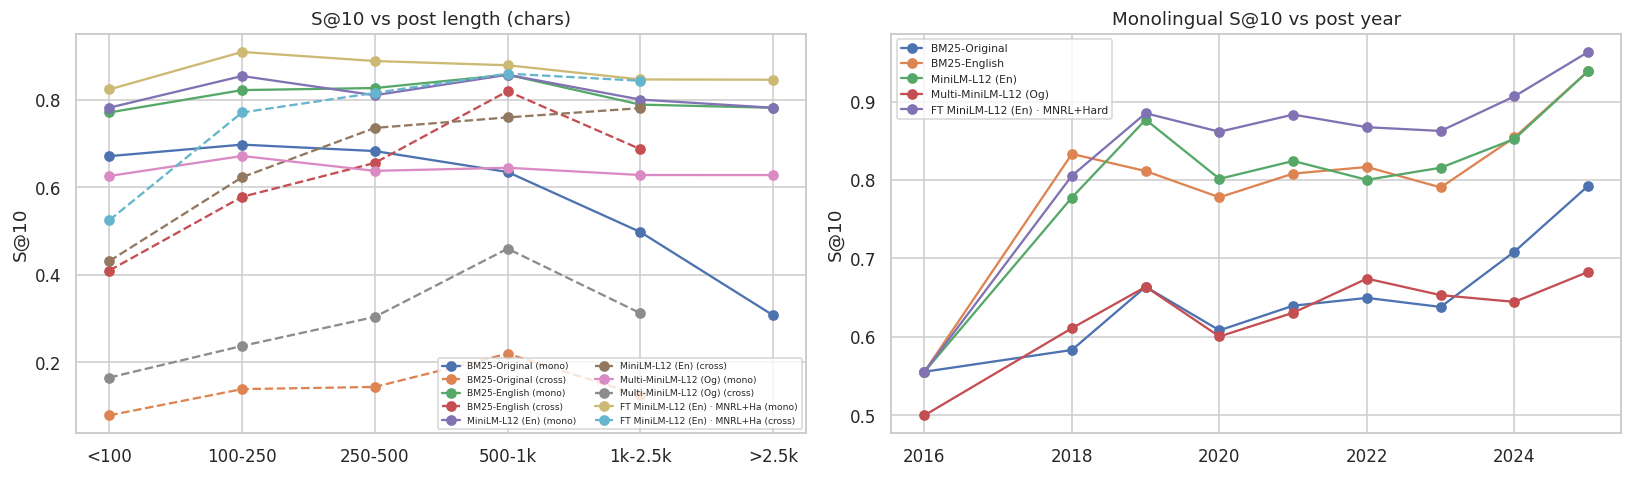

In [26]:
def breakdown(col, names=selected, min_n=20):
    rows = []
    for kind, mask in [("mono", ~EP.is_cross.values), ("cross", EP.is_cross.values)]:
        for val, idx in EP[mask].groupby(col).groups.items():
            if len(idx) < min_n:
                continue
            row = {"dimension": col, "value": val, "kind": kind, "N": len(idx)}
            for n in names:
                row[n] = (RESULTS[n]["r_proto"][idx] <= 10).mean()
            rows.append(row)
    return pd.DataFrame(rows)

EP["covid_related"] = np.where(EP.covid, "COVID-related", "Otherwise")
EP["len_bin"] = pd.cut(EP.len_og, [0, 100, 250, 500, 1000, 2500, 1e9],
                       labels=["<100", "100-250", "250-500", "500-1k", "1k-2.5k", ">2.5k"])
EP["ocr"] = np.where(EP.has_ocr, "post with OCR text", "text only")
bd = pd.concat([breakdown(c) for c in ["covid_related", "verdict", "platform", "ocr"]], ignore_index=True)
bd.to_csv(RES_DIR / "results_breakdowns.csv", index=False)
display(bd.set_index(["dimension", "value", "kind"]).style.format({n: "{:.3f}" for n in selected})
          .background_gradient(subset=selected, cmap="RdYlGn", vmin=0, vmax=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
lb = breakdown("len_bin", min_n=10)
for n in selected:
    for kind, ls in [("mono", "-"), ("cross", "--")]:
        cat_order = {c: i for i, c in enumerate(EP.len_bin.cat.categories)}
        g = lb[lb.kind == kind].assign(o=lambda d: d.value.map(cat_order)).sort_values("o")
        axes[0].plot(g.value.astype(str), g[n], ls, marker="o", label=f"{n[:28]} ({kind})")
axes[0].set(title="S@10 vs post length (chars)", ylabel="S@10")
axes[0].legend(fontsize=6, ncol=2)
yb = breakdown("year", min_n=15)
for n in selected:
    g = yb[yb.kind == "mono"].sort_values("value")
    axes[1].plot(g.value.astype(int), g[n], marker="o", label=n[:30])
axes[1].set(title="Monolingual S@10 vs post year", ylabel="S@10")
axes[1].legend(fontsize=7)
plt.tight_layout(); savefig("results_length_time")

### 12.4 Statistical significance
McNemar's exact test on paired per-link outcomes (hit@10 under the language-aware protocol) for the key comparisons behind RQ1–RQ3.

In [27]:
from scipy.stats import binomtest

def mcnemar(a, b):
    ha, hb = RESULTS[a]["r_proto"] <= 10, RESULTS[b]["r_proto"] <= 10
    n01, n10 = int((~ha & hb).sum()), int((ha & ~hb).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n01 + n10 else 1.0
    return {"A": a, "B": b, "S@10 A": ha.mean(), "S@10 B": hb.mean(), "A only": n10, "B only": n01, "p-value": p}

tests = [("BM25-English", "BM25-Original"), (best_en, best_og), (best_en, "BM25-English")]
best_unsup = max(unsup, key=overall)
best_overall = max(order, key=overall)
if ft_names:
    best_ft = max(ft_names, key=overall)
    tests += [(best_ft, best_unsup)]
    base_ft = [n for n in ft_names if "[baseline]" in n]
    prop_ft = [n for n in ft_names if "[proposed]" in n and RESULTS[n]["metrics"]["version"] == "og"]
    if base_ft and prop_ft:
        tests.append((prop_ft[0], base_ft[0]))
sig = pd.DataFrame([mcnemar(a, b) for a, b in tests if a in RESULTS and b in RESULTS and a != b])
display(sig.style.format({"S@10 A": "{:.3f}", "S@10 B": "{:.3f}", "p-value": "{:.2e}"}))

,A,B,S@10 A,S@10 B,A only,B only,p-value
0,BM25-English,BM25-Original,0.776,0.569,806,64,2.72e-164
1,MiniLM-L12 (En),Multi-MiniLM-L12 (Og),0.791,0.583,815,73,1.95e-159
2,MiniLM-L12 (En),BM25-English,0.791,0.776,290,237,2.34e-02
3,FT MiniLM-L12 (En) · MNRL+HardNeg [proposed],MiniLM-L12 (En),0.853,0.791,264,42,1.70e-40
4,FT Multi-MiniLM (Og) · MNRL+HardNeg [proposed],FT Multi-MiniLM (Og) · RandomNeg [baseline],0.757,0.717,205,63,1.03e-18


## 13. FAISS scalability study (RQ5)
Exact search is linear in the pool size. A production system serving millions of fact-checks would use approximate nearest-neighbour (ANN) indices, trading a little recall for large gains in latency and memory. Using the embeddings of the best encoder, this section compares build time, memory, query latency, recall@10 against exact search, and end-task S@10.

In [28]:
bench_model = max([n for n in RESULTS if n in EMB_KEYS], key=overall)
qk, dk = EMB_KEYS[bench_model]
Qb, Db = np.load(EMB_DIR / f"{qk}.npy"), np.load(EMB_DIR / f"{dk}.npy")
dim, N = Db.shape[1], Db.shape[0]
nlist = max(16, int(math.sqrt(N)))
m_pq = next(m for m in [64, 48, 32, 24, 16, 8, 4] if dim % m == 0 and m <= dim // 4)

def build(kind):
    if kind == "Flat (exact)":
        idx = faiss.IndexFlatIP(dim)
    elif kind == "HNSW32":
        idx = faiss.IndexHNSWFlat(dim, 32, faiss.METRIC_INNER_PRODUCT); idx.hnsw.efConstruction = 80
    elif kind == "IVF-Flat":
        idx = faiss.IndexIVFFlat(faiss.IndexFlatIP(dim), dim, nlist, faiss.METRIC_INNER_PRODUCT)
    else:
        idx = faiss.IndexIVFPQ(faiss.IndexFlatIP(dim), dim, nlist, m_pq, 8, faiss.METRIC_INNER_PRODUCT)
    t0 = time.perf_counter()
    if not idx.is_trained:
        idx.train(Db[np.random.default_rng(SEED).choice(N, min(N, 100 * nlist), replace=False)])
    idx.add(Db)
    build_s = time.perf_counter() - t0
    if kind == "HNSW32":
        idx.hnsw.efSearch = 128
    if kind.startswith("IVF"):
        idx.nprobe = 16
    return idx, build_s

bench = []
I_exact = None
for kind in ["Flat (exact)", "HNSW32", "IVF-Flat", "IVF-PQ"]:
    idx, build_s = build(kind)
    t0 = time.perf_counter(); _, I = idx.search(Qb, TOPK); ms = 1000 * (time.perf_counter() - t0) / len(Qb)
    if I_exact is None:
        I_exact = I
    rec = np.mean([len(set(a[:10]) & set(b[:10])) / 10 for a, b in zip(I, I_exact)])
    s10 = (gold_ranks(I.astype(np.int64), EP.q.values, EP.d.values) <= 10).mean()
    bench.append({"index": kind if kind != "IVF-PQ" else f"IVF-PQ (m={m_pq})", "build_s": build_s, "ms/query": ms,
                  "memory_MB": faiss.serialize_index(idx).nbytes / 1e6, "recall@10 vs exact": rec,
                  "full-pool S@10": s10})
bench = pd.DataFrame(bench).set_index("index")
bench.to_csv(RES_DIR / "faiss_benchmark.csv")
print(f"Model: {bench_model} | pool N={N:,}, dim={dim}, nlist={nlist}")
display(bench.style.format("{:.3f}"))

Model: FT MiniLM-L12 (En) · MNRL+HardNeg [proposed] | pool N=103,535, dim=384, nlist=321


,build_s,ms/query,memory_MB,recall@10 vs exact,full-pool S@10
index,,,,,
Flat (exact),0.107,0.762,159.030,1.000,0.791
HNSW32,43.336,0.669,187.215,0.989,0.785
IVF-Flat,1.911,0.768,160.354,0.900,0.739
IVF-PQ (m=64),31.343,0.477,8.344,0.699,0.726


## 14. Error analysis
Two questions: *where* does the best system fail, and *how many failures are real*? Because many organisations fact-check the same viral claim, a "missed" gold fact-check is often replaced in the top position by a **duplicate fact-check from another organisation**: a correct answer that simply is not labelled (a *hidden positive*). As a cheap proxy, the cell measures how similar the top-1 retrieved claim is to the gold claim under the same encoder and reports the share of failures above several similarity thresholds. Inspect the printed examples to calibrate which threshold indicates a true duplicate for your encoder.

FT MiniLM-L12 (En) · MNRL+HardNeg [proposed]: 525 failed pairs out of 3,574 (14.7%)


,share of failures whose top-1 is close to the gold claim (possible hidden positives)
cos >= 0.6,6.5%
cos >= 0.7,2.1%
cos >= 0.8,0.2%
cos >= 0.9,0.0%


,failure rate
crosslingual,27.3%
monolingual,12.2%
post has OCR,15.1%
post < 60 chars,34.3%
rating: altered photo/video,18.2%
COVID-related,14.9%


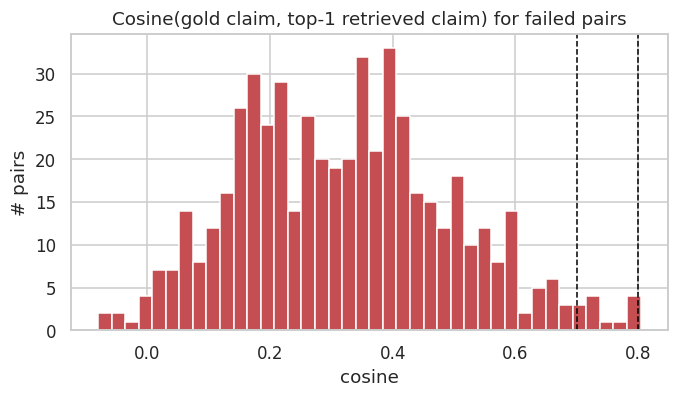

--------------------------------------------------------------------------------------------------------------
[eng post -> eng fact-check | rank 12.0 | cos(gold, top1) 0.66]
POST (en): This isn't some "theory." Rep. Collins and others have CONFIRMED that these are the FACTS through their investigations. HILLARY CLINTON WAS BEHIND THE ENTIRE RUSSIAN COLLUSION HOAX ALL ALONG. THE FBI KNEW THIS AND HAPPIL
GOLD     : "The Russia hoax was Hillary's plan."
TOP-1    : A letter from Director of National Intelligence John Ratcliffe supports the claim that Hillary Clinton planned "the Russia hoax" against Donald Trump in July 2016.
--------------------------------------------------------------------------------------------------------------
[eng post -> eng fact-check | rank inf | cos(gold, top1) 0.38]
POST (en): Notally Tormal. NOTICE: FB and their fact checker, the POYNTER institute funded “SCIENCE FEEDBACK” have now fact checked this post claiming “false information”. In order to do so, They

In [29]:
err_model = bench_model
r = RESULTS[err_model]
fail = EP[r["r_proto"] > 10].copy()
top1 = np.where(fail.is_cross.values, r["rank_full"][fail.q.values, 0], r["rank_lang"][fail.q.values, 0])
fail["top1"] = top1
fail = fail[fail.top1 >= 0]
fail["gold_top1_cos"] = np.einsum("ij,ij->i", Db[fail.d.values], Db[fail.top1.values])
print(f"{err_model}: {len(fail):,} failed pairs out of {len(EP):,} ({len(fail) / len(EP):.1%})")
hp = pd.Series({f"cos >= {t}": (fail.gold_top1_cos >= t).mean() for t in [0.6, 0.7, 0.8, 0.9]},
               name="share of failures whose top-1 is close to the gold claim (possible hidden positives)")
display(hp.to_frame().style.format("{:.1%}"))
fail_rate = pd.DataFrame({
    "failure rate": [(r["r_proto"][m] > 10).mean() for m in
                     [EP.is_cross.values, ~EP.is_cross.values, EP.has_ocr.values, EP.len_og.values < 60,
                      (EP.verdict == "Altered photo/video").values, EP.covid.values]]},
    index=["crosslingual", "monolingual", "post has OCR", "post < 60 chars", "rating: altered photo/video", "COVID-related"])
display(fail_rate.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(fail.gold_top1_cos, bins=40, color="#C44E52")
for t in [0.7, 0.8]:
    ax.axvline(t, color="black", ls="--", lw=1)
ax.set(title="Cosine(gold claim, top-1 retrieved claim) for failed pairs", xlabel="cosine", ylabel="# pairs")
savefig("error_hidden_positives")

show = fail.sample(min(6, len(fail)), random_state=SEED)
for row in show.itertuples():
    print("-" * 110)
    print(f"[{row.post_lang} post -> {row.fc_lang} fact-check | rank {r['r_proto'][row.Index]} | cos(gold, top1) {row.gold_top1_cos:.2f}]")
    print("POST (en):", EQ.text_en.values[row.q][:220])
    print("GOLD     :", POOL.claim_en.values[row.d])
    print("TOP-1    :", POOL.claim_en.values[row.top1])

## 15. Multilingual fact-check retrieval demo
The demo uses the best model that works directly on **original-language** input (no translation step is needed at query time), backed by a FAISS index over the fact-check pool. Each hit shows the claim (with its English translation), language, rating, source and similarity. For an English-version model, a production deployment would place a machine-translation step (e.g. NLLB or a cloud MT API) in front of the encoder.

In [30]:
class FactCheckRetriever:
    def __init__(self, model_path, pool_df, pool_emb):
        self.model = load_encoder(model_path)
        self.pool = pool_df.reset_index(drop=True)
        self.index = faiss.IndexFlatIP(pool_emb.shape[1])
        self.index.add(pool_emb)

    def search(self, text, k=5, same_language=None):
        t0 = time.perf_counter()
        q = self.model.encode([text], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
        S, I = self.index.search(q, k if same_language is None else 2000)
        hits = self.pool.iloc[I[0][I[0] >= 0]].assign(score=S[0][I[0] >= 0])
        if same_language:
            hits = hits[hits.lang == same_language]
        ms = 1000 * (time.perf_counter() - t0)
        cols = ["score", "lang", "claim_og", "claim_en", "rating", "domain", "fact_check_id"]
        return hits.head(k)[cols].reset_index(drop=True), ms

og_models = [n for n in RESULTS if n in EMB_KEYS and RESULTS[n]["metrics"]["version"] == "og"]
demo_name = max(og_models, key=overall)
demo_model_path = RESULTS[demo_name]["metrics"]["model"]
retriever = FactCheckRetriever(demo_model_path, POOL, np.load(EMB_DIR / f"{EMB_KEYS[demo_name][1]}.npy"))
print(f"Demo model: {demo_name}  ({demo_model_path}) | index size {retriever.index.ntotal:,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Demo model: FT Multi-MiniLM (Og) · MNRL+HardNeg [proposed]  (/content/multiclaim_work/models/FT_Multi_MiniLM_Og_MNRL_HardNeg_proposed) | index size 103,535


In [31]:
# (a) Held-out test posts in several languages: is the gold fact-check retrieved?
top_langs = EP.drop_duplicates("q").post_lang.value_counts().index[:8]
demo_posts = EP.drop_duplicates("q")[lambda d: d.post_lang.isin(top_langs)].groupby("post_lang").head(1)
for row in demo_posts.itertuples():
    text = EQ.text_og.values[row.q]
    hits, ms = retriever.search(text, k=5)
    golds = gold_of[EQ.post_id.values[row.q]]
    print("=" * 110)
    print(f"[{row.post_lang}] {text[:200]}")
    for h in hits.itertuples():
        mark = "✓ GOLD" if h.fact_check_id in golds else "      "
        print(f"  {mark} {h.score:.3f} [{h.lang}] {h.claim_og[:90]}" + (f"  ⟶ {h.claim_en[:70]}" if h.lang != "eng" else ""))
    print(f"  ({ms:.0f} ms)")

[eng] 20 Gastanker mit einer Kapazität von je 140.000 m³ sind von der USA in Richtung Europa unterwegs Gratuliere liebe Grüne, diese Tanker brauchen für ihre Fahrt nach Europa soviel Rohöl wie alle Fahrzeug
  ✓ GOLD 0.803 [deu] Zwanzig Flüssiggastanker mit einer Kapazität von je 140.000 Kubikmetern seien von den USA   ⟶ Twenty liquid gas tankers, each with a capacity of 140,000 cubic meter
         0.780 [deu] 20 Flüssiggas-Tanker verbrauchen auf dem Weg nach Europa mehr Treibstoff als der weltweite  ⟶ 20 liquid gas tankers on their way to Europe consume more fuel than th
  ✓ GOLD 0.590 [deu] 20 LNG-Tanker verbrauchen so viel Öl wie alle Autos der Welt in einem Jahr  ⟶ 20 LNG tankers use as much oil as all the cars in the world in a year
         0.571 [hun] 20 LNG-tanker annyi üzemanyagot fogyaszt egy út során, mint a világ összes autója egy év a  ⟶ 20 LNG tankers consume as much fuel on one trip as all the cars in the
         0.547 [spa] Tanques estadounidenses trasladados en tren p

In [32]:
# (b) Free-text queries written in different languages (none of them are in the dataset verbatim)
queries = {
    "English":    "5G towers are spreading the coronavirus",
    "Spanish":    "Beber agua caliente con limón cura el cáncer",
    "Portuguese": "As urnas eletrônicas foram fraudadas nas eleições",
    "French":     "Le vaccin contre le Covid modifie l'ADN humain",
    "Hindi":      "गर्म पानी पीने से कोरोना वायरस खत्म हो जाता है",
    "Arabic":     "صورة لفيضانات في مدينة جدة اليوم",
    "German":     "Bill Gates will die Weltbevölkerung durch Impfungen reduzieren",
    "Indonesian": "Pemerintah akan membagikan bantuan uang tunai lewat WhatsApp",
}
for lang_name, qtext in queries.items():
    hits, ms = retriever.search(qtext, k=3)
    print(f"\n### {lang_name}: {qtext}   ({ms:.0f} ms)")
    display(hits[["score", "lang", "claim_en", "rating", "domain"]])


### English: 5G towers are spreading the coronavirus   (34 ms)


,score,lang,claim_en,rating,domain
0,0.799405,eng,Coronavirus Caused By 5G?,false info!,leadstories.com
1,0.787409,eng,This video shows Chinese people destroying 5G towers over coronavirus fears,false,factuel.afp.com
2,0.774225,spa,The coronavirus is spread by 5G electromagnetic radiation,falso,newtral.es



### Spanish: Beber agua caliente con limón cura el cáncer   (29 ms)


,score,lang,claim_en,rating,domain
0,0.933648,eng,Hot lemon water can treat cancer,false,thip.media
1,0.810793,eng,Drinking warm water cures 'all types of cancer in 9 months',drinking warm water does not cure cancer,fakty.afp.com
2,0.802122,spa,Taking vitamin C by drinking lemon in warm water for coronavirus and cures cancer,falso,factual.afp.com



### Portuguese: As urnas eletrônicas foram fraudadas nas eleições   (29 ms)


,score,lang,claim_en,rating,domain
0,0.834991,por,Voters who denounce electronic voting fraud will be arrested,falso,politica.estadao.com.br
1,0.815937,por,Electronic voting machines are not auditable,fake,oglobo.globo.com
2,0.805089,por,Hacker confirms that electronic voting machines may have been tampered with by the TSE,falso,aosfatos.org


... (6 outputs left out)


### German: Bill Gates will die Weltbevölkerung durch Impfungen reduzieren   (30 ms)


,score,lang,claim_en,rating,domain
0,0.920800,dan,Bill Gates wants to depopulate the world through vaccines,falsk,tjekdet.dk
1,0.888173,tur,The claim that Bill Gates aims to reduce the population through vaccination,yanlış,dogrulukpayi.com
2,0.886379,fra,A newspaper cover from 2011 shows that Bill Gates planned to reduce the world's population through forced vaccination.,le sovereign independent était un journal irlandais connu pour relayer des théories conspirationnistes. l’article dé...,dpa-factchecking.com



### Indonesian: Pemerintah akan membagikan bantuan uang tunai lewat WhatsApp   (28 ms)


,score,lang,claim_en,rating,domain
0,0.661752,eng,You Have to Pay to Use WhatsApp,false,newsmobile.in
1,0.644919,msa,BNI Bank Services Via Whatsapp,salah [fabricated content],cekfakta.com
2,0.624702,msa,The Vice Regent of Nganjuk's WhatsApp message to borrow money,salah [fabricated content],cekfakta.com


In [33]:
# (c) Interactive search box (Jupyter / Colab). Type a claim in any language and press "Search".
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    box = widgets.Textarea(value="Drinking bleach cures COVID-19", layout=widgets.Layout(width="90%", height="70px"))
    k_sl = widgets.IntSlider(value=5, min=1, max=20, description="top-k")
    lang_dd = widgets.Dropdown(options=["any"] + sorted(POOL.lang.value_counts().head(30).index), value="any",
                               description="language")
    btn, out = widgets.Button(description="Search", button_style="primary"), widgets.Output()

    def on_click(_):
        with out:
            clear_output()
            hits, ms = retriever.search(box.value, k=k_sl.value,
                                        same_language=None if lang_dd.value == "any" else lang_dd.value)
            print(f"{len(hits)} results in {ms:.0f} ms")
            display(hits)
    btn.on_click(on_click)
    display(widgets.VBox([box, widgets.HBox([k_sl, lang_dd, btn]), out]))
except ImportError:
    print("ipywidgets not available - use retriever.search('your claim') instead.")

## 16. Artifacts, conclusions, limitations and future work
### 16.1 Persist artifacts

In [34]:
demo_dir = WORK_DIR / "demo"
faiss.write_index(retriever.index, str(demo_dir / "factcheck_index.faiss"))
POOL[["fact_check_id", "claim_og", "claim_en", "lang", "rating", "domain", "year"]].to_parquet(demo_dir / "factcheck_meta.parquet")
json.dump({"demo_model": str(demo_model_path), "run_mode": RUN_MODE, "seed": SEED, "pool_size": len(POOL),
           "eval_posts": len(EQ), "eval_pairs": len(EP), "config": {k: v for k, v in CFG.items()},
           "timings_s": TIMINGS}, open(RES_DIR / "run_config.json", "w"), indent=2, default=str)
print("Artifacts written to", WORK_DIR.resolve())
for p_ in sorted(WORK_DIR.glob("*/*")):
    if p_.is_file() and p_.suffix in {".csv", ".png", ".faiss", ".parquet", ".json"}:
        print(f"  {str(p_.relative_to(WORK_DIR)):55s} {p_.stat().st_size / 1e6:8.2f} MB")

Artifacts written to /content/multiclaim_work
  demo/factcheck_index.faiss                                159.03 MB
  demo/factcheck_meta.parquet                                20.67 MB
  figures/eda_languages.png                                   0.08 MB
  figures/eda_lengths_time_ratings.png                        0.22 MB
  figures/eda_pairs.png                                       0.11 MB
  figures/eda_sources.png                                     0.11 MB
  figures/error_hidden_positives.png                          0.03 MB
  figures/results_length_time.png                             0.24 MB
  figures/results_main.png                                    0.18 MB
  figures/results_per_language.png                            0.08 MB
  figures/results_sk_slb.png                                  0.23 MB
  figures/training_loss.png                                   0.07 MB
  results/faiss_benchmark.csv                                 0.00 MB
  results/results_breakdowns.csv            

In [35]:
# Automatically generated summary of this run
m = res
def g(n, c):
    return m.loc[n, c] if n in m.index else float("nan")
base_ft, prop_ft = (base_ft, prop_ft) if ft_names else ([], [])
lines = [
    f"Best overall method: {best_overall} (mono S@10 {g(best_overall, 'mono_S@10_macro'):.3f}, cross S@10 {g(best_overall, 'cross_S@10_macro'):.3f}).",
    f"RQ1 - translation vs multilingual encoders: best English-version encoder {best_en} reaches cross S@10 {g(best_en, 'cross_S@10_macro'):.3f} "
    f"vs {g(best_og, 'cross_S@10_macro'):.3f} for the best original-version encoder {best_og}.",
    f"BM25-Original is almost blind crosslingually (cross S@10 {g('BM25-Original', 'cross_S@10_macro'):.3f}) and has the strongest "
    f"same-language bias (SLB {g('BM25-Original', 'SLB'):.2f}); translation lifts BM25 to {g('BM25-English', 'cross_S@10_macro'):.3f}.",
]
if ft_names:
    v_ft = RESULTS[best_ft]["metrics"]["version"]
    base_same = max([n for n in unsup if RESULTS[n]["metrics"]["version"] == v_ft and "encoder" in RESULTS[n]["metrics"]["family"]] or unsup, key=overall)
    d_mono = g(best_ft, "mono_S@10_macro") - g(base_same, "mono_S@10_macro")
    d_cross = g(best_ft, "cross_S@10_macro") - g(base_same, "cross_S@10_macro")
    lines.append(f"Supervised fine-tuning: {best_ft} vs unsupervised {base_same}: {d_mono:+.3f} mono / {d_cross:+.3f} cross S@10 "
                 "(see the McNemar table for significance).")
    if base_ft and prop_ft:
        lines.append(f"Hard negatives vs random negatives (Og): {g(prop_ft[0], 'cross_S@10_macro'):.3f} vs {g(base_ft[0], 'cross_S@10_macro'):.3f} cross S@10, "
                     f"{g(prop_ft[0], 'mono_S@10_macro'):.3f} vs {g(base_ft[0], 'mono_S@10_macro'):.3f} mono S@10.")
lines.append(f"FAISS: {bench.index[1]} answers a query in {bench['ms/query'].iloc[1]:.2f} ms with recall@10 {bench['recall@10 vs exact'].iloc[1]:.3f} vs exact search.")
print("\n".join("• " + l for l in lines))

• Best overall method: FT MiniLM-L12 (En) · MNRL+HardNeg [proposed] (mono S@10 0.887, cross S@10 0.730).
• RQ1 - translation vs multilingual encoders: best English-version encoder MiniLM-L12 (En) reaches cross S@10 0.616 vs 0.238 for the best original-version encoder Multi-MiniLM-L12 (Og).
• BM25-Original is almost blind crosslingually (cross S@10 0.107) and has the strongest same-language bias (SLB 0.89); translation lifts BM25 to 0.580.
• Supervised fine-tuning: FT MiniLM-L12 (En) · MNRL+HardNeg [proposed] vs unsupervised MiniLM-L12 (En): +0.048 mono / +0.114 cross S@10 (see the McNemar table for significance).
• Hard negatives vs random negatives (Og): 0.483 vs 0.405 cross S@10, 0.809 vs 0.777 mono S@10.
• FAISS: HNSW32 answers a query in 0.67 ms with recall@10 0.989 vs exact search.


### 16.2 Findings from the reference run
*Reference run: `quick` mode on a Colab T4 GPU, 3,000 test posts (3,574 links, 16.2 % crosslingual), pool of 103,535 fact-checks in 90 languages. Re-running the notebook regenerates every number; `full` mode will give lower absolute scores because of the 4× larger pool.*

| Method | Mono S@10 | Cross S@10 | Full-pool S@10 | MRR@100 | SLB |
|---|---|---|---|---|---|
| BM25-Original | 0.641 | 0.107 | 0.558 | 0.508 | 0.89 |
| BM25-English | 0.836 | 0.580 | 0.693 | 0.570 | 0.31 |
| Multi-MiniLM-L12 (Og) | 0.597 | 0.238 | 0.477 | 0.378 | 0.29 |
| Multi-MiniLM-L12 (En) | 0.780 | 0.489 | 0.616 | 0.482 | 0.28 |
| MiniLM-L12 (En) | 0.839 | 0.616 | 0.699 | 0.553 | 0.31 |
| RRF: BM25-En + MiniLM-L12 (En) | 0.868 | 0.666 | 0.764 | 0.606 | 0.33 |
| FT Multi-MiniLM (Og) · random negatives | 0.777 | 0.395 | 0.635 | 0.526 | 0.37 |
| FT Multi-MiniLM (Og) · hard negatives | 0.809 | 0.483 | 0.679 | 0.566 | 0.35 |
| **FT MiniLM-L12 (En) · hard negatives** | **0.886** | **0.730** | **0.791** | **0.644** | 0.33 |

* **RQ1 — Translate-then-retrieve wins.** The English MiniLM on translated text beats the multilingual MiniLM on original text by +0.24 mono and +0.38 cross S@10 (McNemar p < 0.001). Even the multilingual model scores far better on translated input (cross 0.489 vs 0.238), so translation quality, not model choice alone, drives crosslingual performance.
* **RQ2 — Lexical and semantic signals are complementary.** BM25-English is on par with MiniLM monolingually (0.836 vs 0.839) but behind crosslingually (0.580 vs 0.616). Fusing them with RRF gives the best *unsupervised* system (+0.029 mono, +0.050 cross over the best single model) at zero training cost. Adding the original-text multilingual model to the fusion does not help (0.865 / 0.652). BM25-Original is effectively blind crosslingually (0.107) and returns same-language results 89 % of the time.
* **RQ3 — Hard negatives make fine-tuning substantially more effective.** Fine-tuning MiniLM-L12 (En) with BM25 hard negatives lifts cross S@10 from 0.616 to **0.730** (+11.4 points) and mono from 0.839 to **0.886**, making it the best system overall (p < 0.001). For the multilingual model, hard negatives beat random negatives by +0.032 mono and +0.088 cross S@10 (p < 0.001), while using **one third of the training examples** (20k vs 66.7k) and **2.5× less training time** (151 s vs 379 s).
* **RQ4 — Failure modes.** The best system misses 14.7 % of links. The miss rate is 27.3 % for crosslingual links vs 12.3 % for monolingual ones, and 34.3 % for posts shorter than 60 characters, which carry too little context. Instagram posts are hardest (mono S@10 0.738 vs 0.885 on Facebook), consistent with their image-centric content.
* **RQ5 — ANN is almost free.** HNSW keeps 98.9 % of exact top-10 results (S@10 0.785 vs 0.791) at 0.73 ms/query vs 1.25 ms for exact search. IVF-PQ compresses the index 19× (8 MB vs 159 MB) but loses 0.065 S@10, a sensible option only at much larger scale.
* **Big Data engineering.** The distributed Spark BM25 index (with pruning of terms that appear in more than 5 % of documents) agrees with the exact implementation on 96.6 % of top-10 results with identical S@10, so lexical retrieval can scale out without losing quality.

### 16.3 Limitations
* `quick` mode evaluates a sub-sampled test set against a reduced fact-check pool, so absolute scores are higher than with the full 435k pool. Use `full` mode for final numbers.
* Labels are incomplete: duplicate fact-checks by different organisations are "hidden positives", so all reported scores are lower bounds.
* Text-only methods cannot handle posts whose claim exists only in a video or in an image without readable text.
* The English pipeline depends on machine translation done before this project. A deployed system would need a translation step (and its latency and cost) at query time.

### 16.4 Future work
* Cross-encoder re-ranking (e.g. a multilingual MiniLM / BGE re-ranker) over the top-100 hybrid candidates.
* Fine-tuning the fused system end-to-end, or fine-tuning larger encoders (GTR-T5-Large, multilingual-E5, BGE-M3) in `full` mode.
* Script-aware tokenisation (Thai, Myanmar, Chinese and Japanese are written without spaces) for BM25 on original text.
* Sliding-window encoding of long posts instead of truncation.
* Claim extraction from noisy posts with an LLM before retrieval.
* Temporal evaluation (train on older posts, test on newer) to measure drift as new narratives emerge.
* Automatic de-duplication of fact-checks to recover hidden positives and obtain tighter evaluation.

### 16.5 Project summary for a CV
* Designed and built an end-to-end **multilingual fact-check retrieval system** over 435k fact-checks and 88k social-media posts in 100+ languages.
* Engineered a **PySpark ETL pipeline** (multi-line CSV ingestion, UDF parsing, noise filtering, de-duplication, language normalisation, Parquet) and a **distributed BM25 inverted index** matching exact single-node results on 96.6 % of top-10 hits.
* Benchmarked **BM25, English and multilingual SentenceTransformer encoders, and RRF hybrids** with **FAISS**, using language-aware evaluation with 95 % confidence intervals and McNemar significance tests.
* Fine-tuned encoders with **BM25-mined hard negatives**, raising crosslingual Success@10 from 0.62 to **0.73** (+11 pts), and outperformed random-negative training with **3× less data**.
* Evaluated **FAISS ANN indices** (HNSW, IVF, IVF-PQ), reaching 98.9 % recall at under 1 ms per query, and shipped an interactive multilingual search demo.

### 16.6 Save outputs

In [36]:
# Copy results to Google Drive (Colab) so they survive the end of the session
if IN_COLAB and DRIVE_PROJECT is not None:
    BACKUP = DRIVE_PROJECT / "outputs" / time.strftime("run_%Y%m%d_%H%M")
    for sub_ in ["results", "figures", "demo"]:        # add "models" to keep fine-tuned models (~0.5-1 GB each)
        if (WORK_DIR / sub_).exists():
            shutil.copytree(WORK_DIR / sub_, BACKUP / sub_, dirs_exist_ok=True)
    print("Results copied to", BACKUP)
else:
    print("Results are in", WORK_DIR.resolve())

Results copied to /content/drive/MyDrive/MultiClaim/outputs/run_20261108_0607


In [37]:
spark.stop()
print("Done. Total recorded time: %.1f min" % (sum(TIMINGS.values()) / 60))

Done. Total recorded time: 25.7 min
